# E12 -- Denoiser ablation

Pre-filters each node image with a fixed-parameter denoiser bank before the unchanged F-SIBS pipeline, then measures entropy-coded BPP vs. SSIM / PSNR / NMSE against the original images.

* **Independent:** run this notebook top-to-bottom in a fresh kernel; it needs no other notebook's in-memory state.
* **Needs:** datasets.
* **Writes:** `results/experiment_12/` and `fsibs_eval_outputs/denoiser_experiment/`.
* **Shared code:** imported from the `fsibs` package (see `README.md`); everything experiment-specific is in this notebook.

In [10]:
# ============================================================
# F-SIBS MODULAR - PROJECT LOCATION + IMPORTS
# ============================================================

import sys,time, os
from pathlib import Path

# ------------------------------------------------------------
# Project location
# ------------------------------------------------------------

PROJECT_ROOT = Path("/home/ahmed_omara/F_SIBS_Modular").resolve()
PACKAGE_ROOT = PROJECT_ROOT / "fsibs"

# Validate project root
if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"\nF-SIBS project directory was not found:\n"
        f"  {PROJECT_ROOT}"
    )

# Validate fsibs package
if not PACKAGE_ROOT.exists():
    raise FileNotFoundError(
        f"\nF-SIBS package directory was not found:\n"
        f"  {PACKAGE_ROOT}\n\n"
        f"Project contents:\n"
        + "\n".join(f"  {p.name}" for p in PROJECT_ROOT.iterdir())
    )

if not (PACKAGE_ROOT / "__init__.py").exists():
    raise FileNotFoundError(
        f"\nF-SIBS package exists, but __init__.py was not found:\n"
        f"  {PACKAGE_ROOT / '__init__.py'}"
    )

# Add project root to Python import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Use F-SIBS project as working directory
import os
os.chdir(PROJECT_ROOT)

# ------------------------------------------------------------
# Standard imports
# ------------------------------------------------------------

import os
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fsibs.datasets import build_data_bundle
from fsibs.deps import HAS_PYWT, pywt
from fsibs.entropy_coding import _encode_column_fixed, _entropy_bits_per_symbol, _run_algorithm_generic, entropy_code_sparse_representation, quantize_coeffs
from fsibs.env import setup_environment
from fsibs.federated import F_SIBS_VARIANT_TO_SIBS
from fsibs.metrics import nmse, psnr, ssim
from fsibs.parallel import PBAR_FORMAT, describe
from fsibs.runtime import init_run, new_manifest, save_manifest
from fsibs.selection import prompt_numbers, prompt_selection, resolve_selection

## Configuration
All settings of this experiment.

In [11]:
# ------------------------------------------------------------------------------------
# EXPERIMENT CONFIGURATION -- everything that can differ between experiments lives HERE,
# in this notebook.  Edit freely; no other notebook or module is affected.
# ------------------------------------------------------------------------------------
RUN_DIR_POLICY = "latest"      # "latest": re-use the newest F_SIBS_r_<date>_<n> folder (shared with the other
                               #   notebooks) | "new": start a fresh run folder | or an explicit folder path
INTERACTIVE_SELECTION = False  # True: ask for datasets / algorithms with the original input() menus

# Datasets: any of "coil20", "coil100", "eth80", "epfl", "dino", "temple"
SELECTED_DATASETS = ["coil20", "dino", "temple", "coil100"]
# Algorithms: SIBSk and F-SIBS_k must be selected together (pairing rule); all other baselines are free
SELECTED_ALGORITHMS = [
    "OMP",
    "SIBS1",
    "F-SIBS_1",
    "SIBS2",
    "F-SIBS_2",
    "SIBS3",
    "F-SIBS_3",
    "SIBS4",
    "F-SIBS_4",
]

# ---- shared evaluation-protocol values (defaults from fsibs.protocol; override here for THIS experiment only) ----
from fsibs import protocol as P
RNG_SEED = P.RNG_SEED
COIL_VIEWS = P.COIL_VIEWS
COIL100_VIEWS = P.COIL100_VIEWS
ETH80_VIEWS = P.ETH80_VIEWS
COIL100_MAX_OBJECTS = P.COIL100_MAX_OBJECTS
ETH80_MAX_OBJECTS_PER_CAT = P.ETH80_MAX_OBJECTS_PER_CAT
EPFL_MAX_FRAMES = P.EPFL_MAX_FRAMES
EPFL_TARGET_HW = P.EPFL_TARGET_HW
COIL_N_CROSS_GROUPS = P.COIL_N_CROSS_GROUPS
K_SWEEP = P.K_SWEEP
DELTA = P.DELTA
K_SUMMARY = P.K_SUMMARY
K_GLOBAL = P.K_GLOBAL
N_ROUNDS_FULL = P.N_ROUNDS_FULL
GEOMETRY = P.GEOMETRY
EPS_CONV = P.EPS_CONV

# ---- settings specific to this experiment ----
EXP_DENOISE_USER_SELECTION = ["gaussian", "median", "bilateral", "nlm",
                              "tv_chambolle", "dct_threshold", "wavelet"]
EXP_DENOISE_N_RUNS = 3          # independent runs per (dataset, denoiser); seed = 42+run
EXP_DENOISE_TAU = 0.95          # same default tau as the base Experiment 4 cell
EXP_DENOISE_MAX_NODES = 6       # cap on nodes per group, for runtime; raise if desired
EXP_DENOISE_K_SWEEP = K_SWEEP   # reuse the notebook's existing sparsity grid, unchanged
DYNAMIC_SSIM_BITS_COEFF = 16          # same fixed-point coefficient-resolution assumption as bpp_sparse's
                                       # bits_coeff, reused as the quantization grid the entropy coder is applied to

## Setup
Run folder, selection and (when needed) datasets.

In [12]:
setup_environment(RNG_SEED)                       # warnings, global seed, Matplotlib defaults
describe()                                       # CPU / platform banner
run = init_run(RUN_DIR_POLICY)                    # resolves F_SIBS_r_<date>_<n> and creates its folders
RUN_DIR, FIG_DIR, RESULTS_DIR, DATA_DIR = run.RUN_DIR, run.FIG_DIR, run.RESULTS_DIR, run.DATA_DIR
EXPERIMENT_MANIFEST = new_manifest()              # files this notebook registers as outputs
print("RUN_DIR     :", RUN_DIR)
print("DATA_DIR    :", DATA_DIR)

# ---- algorithm / dataset selection (enforces the SIBSk <-> F-SIBS_k pairing rule) ----
if INTERACTIVE_SELECTION:
    SELECTED_DATASETS, SELECTED_ALGORITHMS = prompt_selection()
    _bits_coeff_sel = prompt_numbers("Choose the coefficient quantization resolution", [8, 10, 12, 14, 16])
    if len(_bits_coeff_sel) != 1:
        raise ValueError("Please select exactly ONE coefficient quantization resolution.")
    DYNAMIC_SSIM_BITS_COEFF = _bits_coeff_sel[0]
sel = resolve_selection(SELECTED_DATASETS, SELECTED_ALGORITHMS)
SELECTED_DATASETS, SELECTED_ALGORITHMS = sel.SELECTED_DATASETS, sel.SELECTED_ALGORITHMS
ACTIVE_F_SIBS_VARIANTS = sel.ACTIVE_F_SIBS_VARIANTS

# ---- datasets: acquisition (cached in DATA_DIR), node pools, federated groups ----
data = build_data_bundle(
    SELECTED_DATASETS, DATA_DIR,
    coil_views=COIL_VIEWS, coil100_views=COIL100_VIEWS, eth80_views=ETH80_VIEWS,
    coil100_max_objects=COIL100_MAX_OBJECTS, eth80_max_objects_per_cat=ETH80_MAX_OBJECTS_PER_CAT,
    epfl_max_frames=EPFL_MAX_FRAMES, epfl_target_hw=EPFL_TARGET_HW,
    coil_n_cross_groups=COIL_N_CROSS_GROUPS)
POOLS, PHI, GROUPS = data.POOLS, data.PHI, data.GROUPS
_pick_group = data.pick_group

effective_cpu_count() = 96 | platform = Linux | MULTIPROCESSING_AVAILABLE = True
RUN_DIR     : /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1
DATA_DIR    : /home/ahmed_omara/F_SIBS_Modular/fsibs_data
EXPERIMENT CONFIGURATION

Selected datasets:
    COIL-20
    Middlebury Dino
    Middlebury Temple
    COIL-100

Selected SIBS <-> F-SIBS pairs:
    SIBS1  + F-SIBS_1 
    SIBS2  + F-SIBS_2 
    SIBS3  + F-SIBS_3 
    SIBS4  + F-SIBS_4 

Selected other baselines:
    OMP

Final algorithms (SELECTED_METHODS):
    OMP
    SIBS1
    F-SIBS_1
    SIBS2
    F-SIBS_2
    SIBS3
    F-SIBS_3
    SIBS4
    F-SIBS_4
Configuration valid -- proceeding with the experiment campaign.
Active local SIBS methods (from SELECTED_BASELINES / SELECTED_SIBS_VARIANTS): ['SIBS1', 'SIBS2', 'SIBS3', 'SIBS4']
Active F-SIBS variants (from the user's paired SIBSk<->F-SIBS_k selection): ['F-SIBS_1', 'F-SIBS_2', 'F-SIBS_3', 'F-SIBS_4']


Middlebury datasets: 100% complete |██████████| 2/2 [00:00<00:00]

COIL-20 images: 1440 files in /home/ahmed_omara/F_SIBS_Modular/fsibs_data/Image_Classfiation_Coil20-master/dataset
dino    images: 16 PNGs in /home/ahmed_omara/F_SIBS_Modular/fsibs_data/dinoSparseRing
temple  images: 16 PNGs in /home/ahmed_omara/F_SIBS_Modular/fsibs_data/templeSparseRing
downloading http://www.cad.zju.edu.cn/home/dengcai/Data/MLData/COIL-100.zip


  COIL-100 mirror failed (http://www.cad.zju.edu.cn/home/dengcai/Data/MLData/COIL-100.zip): HTTPError('404 Client Error: Not Found for url: http://www.cad.zju.edu.cn/home/dengcai/Data/MLData/COIL-100.zip')
downloading https://www.cs.columbia.edu/CAVE/databases/SLAM_coil-20_coil-100/coil-100/coil-100.zip
saved /home/ahmed_omara/F_SIBS_Modular/fsibs_data/coil-100.zip (130.7 MB)
COIL-100 images: 7200 in /home/ahmed_omara/F_SIBS_Modular/fsibs_data/coil-100
ETH-80: not selected -> acquisition skipped
EPFL: not selected -> acquisition skipped


COIL-20 objects: 100% complete |██████████| 20/20 [00:00<00:00]
dino frames: 100% complete |██████████| 16/16 [00:00<00:00]
temple frames: 100% complete |██████████| 16/16 [00:00<00:00]
COIL-100 objects: 100% complete |██████████| 100/100 [00:00<00:00]

Node catalogue (one view of one object per node):
dataset  nodes  subjects  img_shape
 coil20     80        20 (128, 128)
   dino     16         1  (96, 128)
 temple     16         1  (96, 128)
coil100    100       100 (128, 128)

federated node groups:
  coil20_same_object      20 groups | 4 members each
  coil20_cross_object      5 groups | 4 members each
  coil100_same_object    100 groups | 1 members each
  coil100_cross_object    25 groups | 4 members each
  dino_ring                1 groups | 16 members each
  temple_ring              1 groups | 16 members each

NODE_CATALOG built: 212 rows across 4 datasets


## Experiment-specific helpers
Defined here (not in `fsibs`) because no other experiment uses them.

In [14]:
# Optional back-ends of the denoiser bank (each missing library just skips its denoiser)
try:
    from scipy.ndimage import gaussian_filter as _dn_gaussian_filter, \
        median_filter as _dn_median_filter
    HAS_SCIPY_NDIMAGE = True
except ImportError:
    HAS_SCIPY_NDIMAGE = False
    print("NOTE: scipy.ndimage not available -- Gaussian/Median denoisers skipped.")

try:
    from skimage.restoration import denoise_bilateral as _dn_bilateral_fn, \
        denoise_nl_means as _dn_nlm_fn, denoise_tv_chambolle as _dn_tv_fn
    HAS_SKIMAGE_RESTORATION = True
except ImportError:
    HAS_SKIMAGE_RESTORATION = False
    print("NOTE: skimage.restoration not available -- Bilateral/NLM/TV "
          "denoisers skipped.")

try:
    from scipy.fft import dctn as _dn_dctn, idctn as _dn_idctn
    HAS_SCIPY_FFT = True
except ImportError:
    HAS_SCIPY_FFT = False
    print("NOTE: scipy.fft not available -- DCT-threshold denoiser skipped.")

In [15]:
DENOISE_FIXED_PARAMS = {
    "gaussian":      {"sigma": 1.0},
    "median":        {"size": 3},
    "bilateral":     {"sigma_color": 0.05, "sigma_spatial": 1.0},
    "nlm":           {"h": 10.0, "patch_size": 5, "patch_distance": 6},
    "tv_chambolle":  {"weight": 10.0},
    "dct_threshold": {"threshold": 12.0},
    "wavelet":       {"wavelet": "db2", "level": 2, "threshold": 10.0, "mode": "soft"},
}

def _dn_call_compat(fn, image, **kwargs):
    """skimage changed `multichannel=False` -> `channel_axis=None` across
    versions; try the modern kw first, fall back to the legacy one."""
    try:
        return fn(image, channel_axis=None, **kwargs)
    except TypeError:
        return fn(image, multichannel=False, **kwargs)

def _denoise_none(img):
    return img.copy()

def _denoise_gaussian(img):
    p = DENOISE_FIXED_PARAMS["gaussian"]
    return _dn_gaussian_filter(img, sigma=p["sigma"])

def _denoise_median(img):
    p = DENOISE_FIXED_PARAMS["median"]
    return _dn_median_filter(img, size=p["size"])

def _denoise_bilateral(img):
    p = DENOISE_FIXED_PARAMS["bilateral"]
    x01 = np.clip(img, 0, 255) / 255.0
    out = _dn_call_compat(_dn_bilateral_fn, x01,
                          sigma_color=p["sigma_color"], sigma_spatial=p["sigma_spatial"])
    return out * 255.0

def _denoise_nlm(img):
    p = DENOISE_FIXED_PARAMS["nlm"]
    return _dn_call_compat(_dn_nlm_fn, img, h=p["h"], patch_size=p["patch_size"],
                           patch_distance=p["patch_distance"], fast_mode=True)

def _denoise_tv(img):
    p = DENOISE_FIXED_PARAMS["tv_chambolle"]
    return _dn_call_compat(_dn_tv_fn, img, weight=p["weight"])

def _denoise_dct(img):
    p = DENOISE_FIXED_PARAMS["dct_threshold"]
    coeffs = _dn_dctn(img, norm="ortho")
    coeffs[np.abs(coeffs) < p["threshold"]] = 0.0
    return _dn_idctn(coeffs, norm="ortho")

def _denoise_wavelet(img):
    p = DENOISE_FIXED_PARAMS["wavelet"]
    coeffs = pywt.wavedec2(img, wavelet=p["wavelet"], level=p["level"])
    coeffs_thr = [coeffs[0]] + [
        tuple(pywt.threshold(c, value=p["threshold"], mode=p["mode"]) for c in detail)
        for detail in coeffs[1:]
    ]
    rec = pywt.waverec2(coeffs_thr, wavelet=p["wavelet"])
    return rec[:img.shape[0], :img.shape[1]]

DENOISER_REGISTRY = {"none": {"fn": _denoise_none, "params": {}}}
if HAS_SCIPY_NDIMAGE:
    DENOISER_REGISTRY["gaussian"] = {"fn": _denoise_gaussian, "params": DENOISE_FIXED_PARAMS["gaussian"]}
    DENOISER_REGISTRY["median"]   = {"fn": _denoise_median,   "params": DENOISE_FIXED_PARAMS["median"]}
if HAS_SKIMAGE_RESTORATION:
    DENOISER_REGISTRY["bilateral"]    = {"fn": _denoise_bilateral, "params": DENOISE_FIXED_PARAMS["bilateral"]}
    DENOISER_REGISTRY["nlm"]          = {"fn": _denoise_nlm,       "params": DENOISE_FIXED_PARAMS["nlm"]}
    DENOISER_REGISTRY["tv_chambolle"] = {"fn": _denoise_tv,        "params": DENOISE_FIXED_PARAMS["tv_chambolle"]}
if HAS_SCIPY_FFT:
    DENOISER_REGISTRY["dct_threshold"] = {"fn": _denoise_dct, "params": DENOISE_FIXED_PARAMS["dct_threshold"]}
if globals().get("HAS_PYWT", False):
    DENOISER_REGISTRY["wavelet"] = {"fn": _denoise_wavelet, "params": DENOISE_FIXED_PARAMS["wavelet"]}

## Experiment

Denoiser experiment -- active denoisers (fixed parameters shown):
  none           {}
  gaussian       {'sigma': 1.0}
  median         {'size': 3}
  bilateral      {'sigma_color': 0.05, 'sigma_spatial': 1.0}
  nlm            {'h': 10.0, 'patch_size': 5, 'patch_distance': 6}
  tv_chambolle   {'weight': 10.0}
  dct_threshold  {'threshold': 12.0}
  wavelet        {'wavelet': 'db2', 'level': 2, 'threshold': 10.0, 'mode': 'soft'}

Denoiser experiment will run on 3 dataset(s): coil20 (coil20_same_object, group coil20_obj01, N=4), dino (dino_ring, group dino_ring, N=6), temple (temple_ring, group temple_ring, N=6)
F-SIBS config reused unchanged: variant=F-SIBS_1 (local encoder SIBS1), DELTA=8, K_SUMMARY=8, K_GLOBAL=16, N_ROUNDS_FULL=8, tau=0.95, K_SWEEP=[2, 4, 8, 16, 24], 3 runs/configuration
Resuming denoiser experiment from checkpoint: 360 rows already completed for 72 (dataset, denoiser, run) combination(s).
0 of 72 (dataset, denoiser, run) combinations remaining after checkpoint skip.


Denoiser experiment sweep:   0% complete |          | 0/0 [00:00<?]


Denoiser experiment -- summary per (dataset, denoiser), averaged over K_SWEEP and 3 runs:
dataset      denoiser  avg_BPP  std_BPP  avg_compression_ratio  avg_SSIM  std_SSIM  avg_PSNR  std_PSNR  avg_NMSE  std_NMSE  avg_denoise_time_s  avg_fsibs_time_s  avg_total_time_s  n_runs
 coil20     bilateral   2.9983   1.1396                 3.0269    0.7975    0.0898   27.9621    3.0220    0.0070    0.0049              0.0235            3.4809            3.5045       3
 coil20 dct_threshold   3.0342   1.1041                 2.9626    0.8135    0.1041   29.2565    4.0132    0.0060    0.0051              0.0022            3.6001            3.6023       3
 coil20      gaussian   2.8956   1.0278                 3.0855    0.8425    0.1056   28.6273    3.3286    0.0063    0.0048              0.0022            3.1086            3.1107       3
 coil20        median   2.8660   1.0666                 3.1499    0.8267    0.1029   29.5488    4.1694    0.0058    0.0049              0.0081            3.3514 

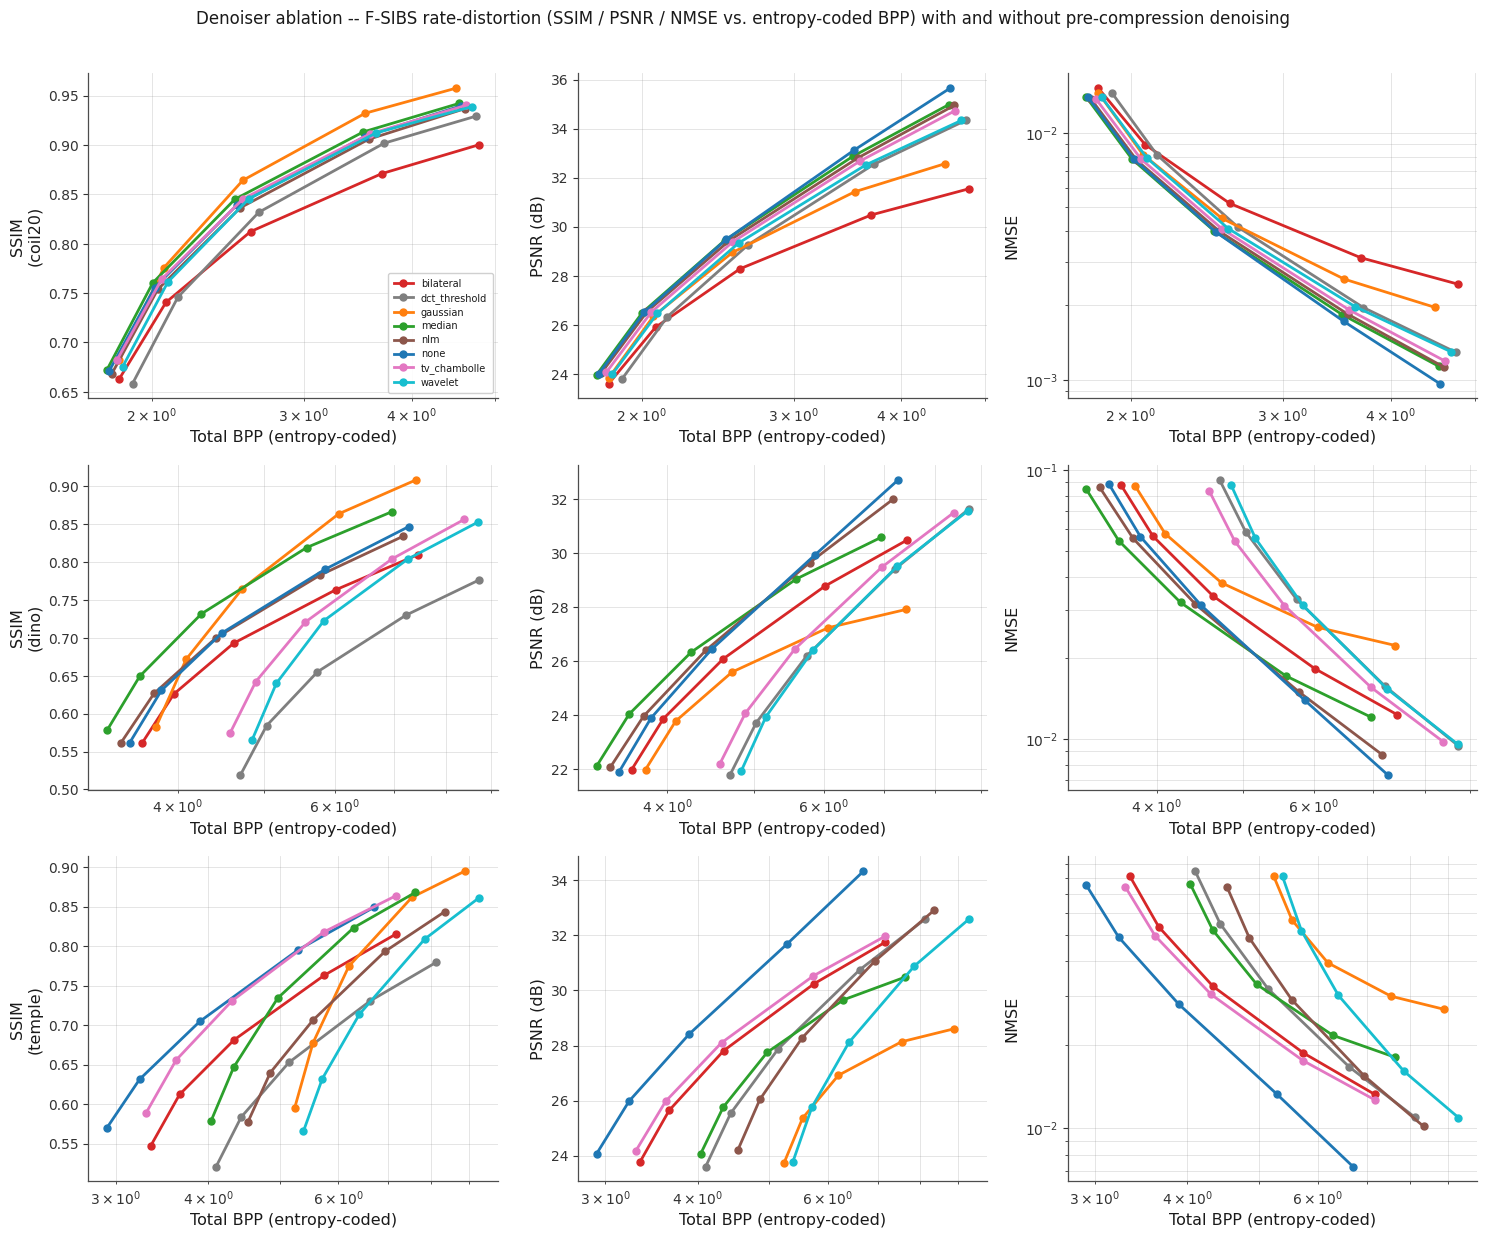

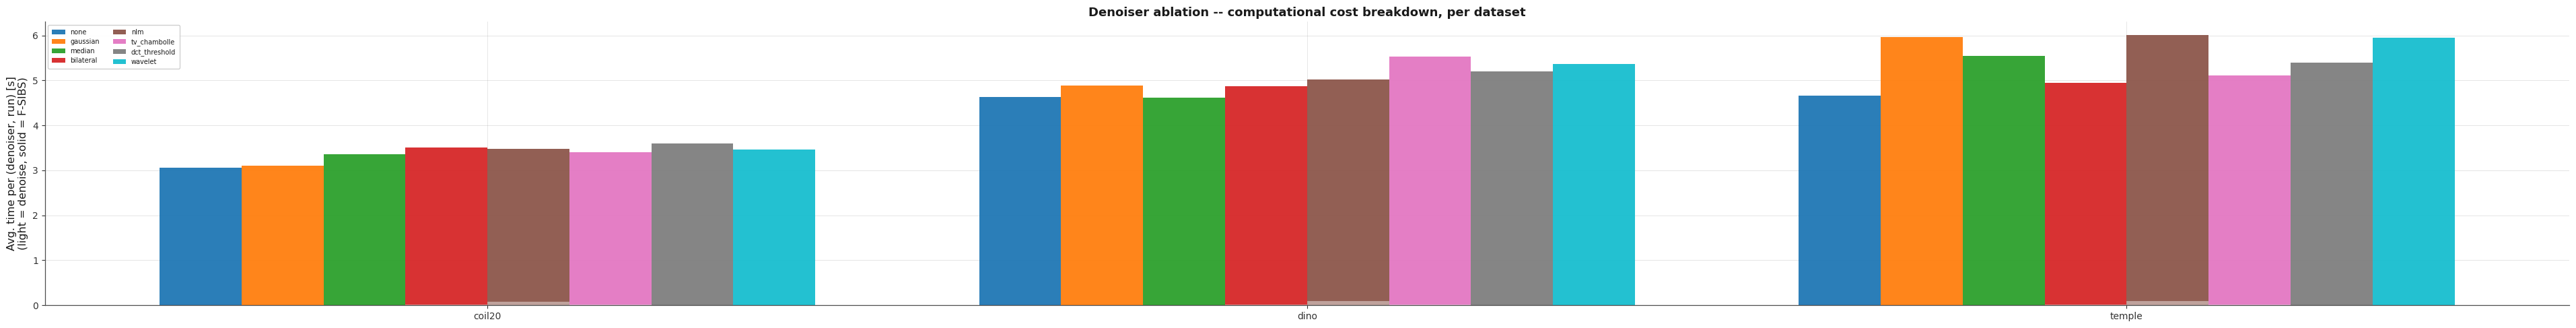

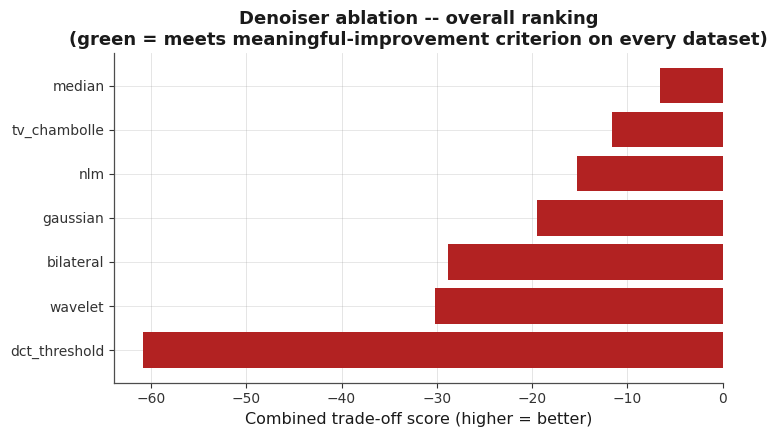


Saved tables: /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_raw_runs.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_rd_curve_by_dataset_denoiser_k.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_summary_by_dataset.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_vs_baseline_per_dataset.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_overall_ranking.csv
Saved figures: /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_rd_curves_ssim_psnr_nmse.png , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_time_breakdown.png , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_overall_ranking.png
E12 self-registered in EXPERIMENT_MANIFEST:

In [6]:
# ============================================================
# EXPERIMENT 12 - Denoiser Ablation (original standalone denoiser
# cell, run part). Pre-filters each node image with the fixed-parameter
# denoiser bank (DENOISER_REGISTRY, Cell 2 Section 2.7) before the
# UNCHANGED F-SIBS pipeline, then measures entropy-coded BPP vs.
# SSIM/PSNR/NMSE against the ORIGINAL images. EXP_DENOISE_* knobs live
# in Cell 1 (EXP_DENOISE_METHODS is derived here from the registry).
# Outputs are written under results/experiment_12/ (via the cell's own
# save helpers) and fsibs_eval_outputs/denoiser_experiment/.
# ============================================================

EXP_DENOISE_METHODS = ["none"] + [d for d in EXP_DENOISE_USER_SELECTION
                                  if d in DENOISER_REGISTRY and d != "none"]

print("Denoiser experiment -- active denoisers (fixed parameters shown):")
for _d in EXP_DENOISE_METHODS:
    print("  %-14s %s" % (_d, DENOISER_REGISTRY[_d]["params"]))
_skipped_dn = [d for d in EXP_DENOISE_USER_SELECTION if d not in DENOISER_REGISTRY]
if _skipped_dn:
    print("  (skipped, dependency unavailable):", _skipped_dn)

# (_dn_pick_group now aliases the shared _pick_group from Cell 2 --
#  the original per-cell copy had the identical body.)
_dn_pick_group = _pick_group


EXP_DENOISE_DATASETS = [ds for ds in SELECTED_DATASETS if ds in POOLS]
EXP_DENOISE_GROUPS = {}
for ds in EXP_DENOISE_DATASETS:
    cfg, g = _dn_pick_group(ds)
    if g is not None:
        EXP_DENOISE_GROUPS[ds] = (cfg, g)

if not EXP_DENOISE_GROUPS:
    print("Skipped: denoiser experiment -- no selected dataset provides a "
          "usable federated node group.")
else:
    _vname_dn, _vfn_dn = next(iter(ACTIVE_F_SIBS_VARIANTS.items()))
    _alg_dn = F_SIBS_VARIANT_TO_SIBS.get(_vname_dn, "SIBS1")
    print("\nDenoiser experiment will run on %d dataset(s): %s"
          % (len(EXP_DENOISE_GROUPS),
             ", ".join("%s (%s, group %s, N=%d)"
                       % (ds, cfg, g["group_id"], min(len(g["node_idx"]), EXP_DENOISE_MAX_NODES))
                       for ds, (cfg, g) in EXP_DENOISE_GROUPS.items())))
    print("F-SIBS config reused unchanged: variant=%s (local encoder %s), "
          "DELTA=%d, K_SUMMARY=%d, K_GLOBAL=%d, N_ROUNDS_FULL=%d, tau=%.2f, "
          "K_SWEEP=%s, %d runs/configuration"
          % (_vname_dn, _alg_dn, DELTA, K_SUMMARY, K_GLOBAL, N_ROUNDS_FULL,
             EXP_DENOISE_TAU, EXP_DENOISE_K_SWEEP, EXP_DENOISE_N_RUNS))

    _dn_out_dir = os.path.join(FIG_DIR, "denoiser_experiment")
    _dn_results_dir = os.path.join(RESULTS_DIR, "experiment_denoiser")
    os.makedirs(_dn_out_dir, exist_ok=True)
    os.makedirs(_dn_results_dir, exist_ok=True)
    import time as _dn_time
    def _dn_save_table(df, name):
        p1 = os.path.join(_dn_results_dir, name + ".csv")
        p2 = os.path.join(_dn_out_dir, name + ".csv")
        df.to_csv(p1, index=False); df.to_csv(p2, index=False)
        return p1

    def _dn_save_figure(fig, name):
        p1 = os.path.join(_dn_results_dir, name + ".png")
        p2 = os.path.join(_dn_out_dir, name + ".png")
        fig.savefig(p1, dpi=200, bbox_inches="tight")
        fig.savefig(p2, dpi=200, bbox_inches="tight")
        return p1

    # -----------------------------------------------------------
    # STEP 2: main sweep -- (dataset, denoiser, run) -> federation once,
    #   then a fixed-k re-encoding sweep over K_SWEEP for the R-D curve
    # -----------------------------------------------------------
    EXP_DENOISE_ROWS = []
    _dn_tasks = [(ds, denoiser, run)
                for ds in EXP_DENOISE_GROUPS
                for denoiser in EXP_DENOISE_METHODS
                for run in range(EXP_DENOISE_N_RUNS)]

    # ---- CHECKPOINT (completes the run interrupted at 81% of the sweep):
    # load whatever (dataset, denoiser, run) combinations a previous,
    # interrupted pass already wrote to denoise_raw_runs.csv, and skip them
    # here instead of redoing the whole sweep from scratch. ----
    _dn_checkpoint_path = os.path.join(_dn_out_dir, "denoise_raw_runs.csv")
    _dn_done_keys = set()
    if os.path.exists(_dn_checkpoint_path):
        try:
            _dn_prev = pd.read_csv(_dn_checkpoint_path)
            EXP_DENOISE_ROWS = _dn_prev.to_dict("records")
            _dn_done_keys = set((r["dataset"], r["denoiser"], r["run"])
                                for r in EXP_DENOISE_ROWS)
            print("Resuming denoiser experiment from checkpoint: %d rows already "
                  "completed for %d (dataset, denoiser, run) combination(s)."
                  % (len(EXP_DENOISE_ROWS), len(_dn_done_keys)))
        except Exception as _dnck:
            print("Could not read denoiser-experiment checkpoint (%s) -- "
                  "starting fresh." % repr(_dnck))

    _dn_tasks_remaining = [t for t in _dn_tasks if t not in _dn_done_keys]
    print("%d of %d (dataset, denoiser, run) combinations remaining after "
          "checkpoint skip." % (len(_dn_tasks_remaining), len(_dn_tasks)))

    def _dn_checkpoint_save():
        _df = pd.DataFrame(EXP_DENOISE_ROWS)
        _df.to_csv(_dn_checkpoint_path, index=False)
        _df.to_csv(os.path.join(_dn_results_dir, "denoise_raw_runs.csv"), index=False)

    for (ds, denoiser, run) in tqdm(_dn_tasks_remaining, desc="Denoiser experiment sweep",
                                    bar_format=PBAR_FORMAT):
        cfg, g = EXP_DENOISE_GROUPS[ds]
        node_idx = g["node_idx"][:EXP_DENOISE_MAX_NODES]
        N_nodes = len(node_idx)
        imgs_orig = [POOLS[ds][i]["img"] for i in node_idx]
        Phi_ds = PHI[ds]
        h, w = GEOMETRY[ds] if ds in GEOMETRY else imgs_orig[0].shape
        n_px = h * w
        seed = 42 + run

        # ---- denoise every node image (timed); deterministic, fixed params ----
        t0 = _dn_time.time()
        denoise_fn = DENOISER_REGISTRY[denoiser]["fn"]
        imgs_dn = [np.clip(denoise_fn(X), 0, 255) for X in imgs_orig]
        denoise_time_s = _dn_time.time() - t0

        # ---- federation (once per run), exactly like the base Exp.4 cell ----
        t1 = _dn_time.time()
        try:
            fed = _vfn_dn(imgs_dn, Phi_ds, DELTA, K_SUMMARY, K_global=K_GLOBAL,
                         n_rounds=N_ROUNDS_FULL, tau=EXP_DENOISE_TAU, eps_conv=EPS_CONV,
                         seed=seed, return_transmitted_vectors=True)
        except Exception as _dn_e:
            print("  [ERROR] denoiser task (dataset=%s, denoiser=%s, run=%d) -> %s: %s"
                  % (ds, denoiser, run, type(_dn_e).__name__, _dn_e))
            continue
        all_vecs = np.concatenate(
            [v for v in fed["transmitted_vectors_history"] if v.shape[1] > 0], axis=1
        ) if sum(v.shape[1] for v in fed["transmitted_vectors_history"]) > 0 else np.zeros((h, 0))
        if all_vecs.shape[1] > 0:
            q, _ = quantize_coeffs(all_vecs.ravel(), bits=DYNAMIC_SSIM_BITS_COEFF)
            uplink_entropy_bits = float(_entropy_bits_per_symbol(q) * all_vecs.size)
        else:
            uplink_entropy_bits = 0.0
        federated_comm_bpp = uplink_entropy_bits / (N_nodes * n_px)

        Psi_g = fed["global_dict"]
        if Psi_g.shape[1] > 0:
            Phi_aug = np.column_stack([Phi_ds, Psi_g])
            nrm = np.linalg.norm(Phi_aug, axis=0, keepdims=True); nrm[nrm < 1e-12] = 1.0
            Phi_aug = Phi_aug / nrm
        else:
            Phi_aug = Phi_ds
        N_dict = Phi_aug.shape[1]

        # ---- fixed-k re-encoding sweep over K_SWEEP, entropy-coded, scored
        #      against the ORIGINAL (non-denoised) image ----------------------
        _task_rows = []
        for k in EXP_DENOISE_K_SWEEP:
            coef_bpps, ssims, psnrs, nmses = [], [], [], []
            for X_orig, X_dn in zip(imgs_orig, imgs_dn):
                Xh, K_col, idx, coef = _run_algorithm_generic(
                    _alg_dn, X_dn, Phi_aug, DELTA,
                    lambda xo, et, ph, off, _k=k: _encode_column_fixed(xo, et, ph, off, _k))
                Xh = np.clip(Xh, 0, 255)
                enc = entropy_code_sparse_representation(idx, coef, [k], N_dict,
                                                         bits_coeff=DYNAMIC_SSIM_BITS_COEFF)
                coef_bpps.append(enc["entropy_bits"] / n_px)
                ssims.append(ssim(X_orig, Xh))
                psnrs.append(psnr(X_orig, Xh))
                nmses.append(nmse(X_orig, Xh))

            coef_bpp = float(np.mean(coef_bpps))
            total_bpp = coef_bpp + federated_comm_bpp
            _task_rows.append({
                "dataset": ds, "config": cfg, "group_id": g["group_id"],
                "denoiser": denoiser, "N_nodes": N_nodes, "run": run, "k": k,
                "achieved_SSIM": float(np.mean(ssims)),
                "achieved_PSNR": float(np.mean(psnrs)),
                "achieved_NMSE": float(np.mean(nmses)),
                "coefficient_BPP_entropy_coded": coef_bpp,
                "federated_communication_BPP": federated_comm_bpp,
                "total_BPP_entropy_coded": total_bpp,
                "compression_ratio": 8.0 / total_bpp,
            })

        fsibs_time_s = _dn_time.time() - t1
        # timing embedded directly on every per-k row of this task (a single
        # (dataset, denoiser, run) combination is one denoise + one
        # federation run, timed once, shared by every k in the sweep) --
        # this also means a single checkpointed DataFrame carries both the
        # R-D and timing columns, with no separate merge step needed.
        for _row in _task_rows:
            _row["denoise_time_s"] = denoise_time_s
            _row["fsibs_time_s"] = fsibs_time_s
            _row["total_time_s"] = denoise_time_s + fsibs_time_s
        EXP_DENOISE_ROWS.extend(_task_rows)

        # checkpoint after EVERY (dataset, denoiser, run) combination, not
        # just at the end of the whole sweep, so an interruption anywhere
        # never loses more than the one combination in flight
        _dn_checkpoint_save()

    EXP_DENOISE_RAW_DF = pd.DataFrame(EXP_DENOISE_ROWS)
    _dn_raw_path = _dn_save_table(EXP_DENOISE_RAW_DF, "denoise_raw_runs")

    # -----------------------------------------------------------
    # STEP 3: aggregate over runs -- (a) the R-D curve per (dataset,
    #   denoiser, k), mean +/- std; (b) one summary row per (dataset,
    #   denoiser), averaged over k AND runs, incl. timing
    # -----------------------------------------------------------
    _rd_metric_cols = ["achieved_SSIM", "achieved_PSNR", "achieved_NMSE",
                       "total_BPP_entropy_coded", "compression_ratio"]
    _rd_agg = EXP_DENOISE_RAW_DF.groupby(["dataset", "denoiser", "k"])[_rd_metric_cols].agg(
        ["mean", "std"])
    _rd_agg.columns = ["%s_%s" % (c, s) for c, s in _rd_agg.columns]
    EXP_DENOISE_RD_DF = _rd_agg.reset_index()
    EXP_DENOISE_RD_DF["n_runs"] = EXP_DENOISE_N_RUNS
    _dn_rd_path = _dn_save_table(EXP_DENOISE_RD_DF, "denoise_rd_curve_by_dataset_denoiser_k")

    EXP_DENOISE_SUMMARY_DF = (
        EXP_DENOISE_RAW_DF.groupby(["dataset", "denoiser"])
        .agg(avg_BPP=("total_BPP_entropy_coded", "mean"),
             std_BPP=("total_BPP_entropy_coded", "std"),
             avg_compression_ratio=("compression_ratio", "mean"),
             avg_SSIM=("achieved_SSIM", "mean"), std_SSIM=("achieved_SSIM", "std"),
             avg_PSNR=("achieved_PSNR", "mean"), std_PSNR=("achieved_PSNR", "std"),
             avg_NMSE=("achieved_NMSE", "mean"), std_NMSE=("achieved_NMSE", "std"),
             avg_denoise_time_s=("denoise_time_s", "mean"),
             avg_fsibs_time_s=("fsibs_time_s", "mean"),
             avg_total_time_s=("total_time_s", "mean"),
             n_runs=("run", "nunique"))
        .reset_index())
    _dn_summary_path = _dn_save_table(EXP_DENOISE_SUMMARY_DF, "denoise_summary_by_dataset")

    print("\nDenoiser experiment -- summary per (dataset, denoiser), averaged "
          "over K_SWEEP and %d runs:" % EXP_DENOISE_N_RUNS)
    print(EXP_DENOISE_SUMMARY_DF.round(4).to_string(index=False))

    # -----------------------------------------------------------
    # STEP 4: automatic comparison vs. the "none" (no-denoising) baseline
    # -----------------------------------------------------------
    EXP_DENOISE_MIN_BPP_IMPROVEMENT_PCT = 2.0   # bpp must drop by >= this % ...
    EXP_DENOISE_MAX_ACCEPTABLE_SSIM_LOSS = 0.01 # ... while SSIM drops by <= this
    EXP_DENOISE_SCORE_W_BPP = 1.0        # score weight: % BPP reduction
    EXP_DENOISE_SCORE_W_SSIM_LOSS = 1000.0  # score weight: SSIM loss (heavily penalised)
    EXP_DENOISE_SCORE_W_TIME = 0.05      # score weight: % extra total compute time

    _cmp_rows = []
    for ds in EXP_DENOISE_GROUPS:
        _s = EXP_DENOISE_SUMMARY_DF[EXP_DENOISE_SUMMARY_DF["dataset"] == ds]
        _base = _s[_s["denoiser"] == "none"]
        if _base.empty:
            continue
        _base = _base.iloc[0]
        for _, row in _s[_s["denoiser"] != "none"].iterrows():
            bpp_change_pct = (row["avg_BPP"] - _base["avg_BPP"]) / _base["avg_BPP"] * 100
            ssim_change = row["avg_SSIM"] - _base["avg_SSIM"]
            psnr_change_db = row["avg_PSNR"] - _base["avg_PSNR"]
            nmse_change_pct = (row["avg_NMSE"] - _base["avg_NMSE"]) / max(_base["avg_NMSE"], 1e-12) * 100
            time_overhead_pct = (row["avg_total_time_s"] - _base["avg_total_time_s"]) / _base["avg_total_time_s"] * 100
            _cmp_rows.append({
                "dataset": ds, "denoiser": row["denoiser"],
                "bpp_change_pct": bpp_change_pct, "ssim_change": ssim_change,
                "psnr_change_db": psnr_change_db, "nmse_change_pct": nmse_change_pct,
                "time_overhead_pct": time_overhead_pct,
                "meaningful_improvement": bool(
                    bpp_change_pct <= -EXP_DENOISE_MIN_BPP_IMPROVEMENT_PCT and
                    ssim_change >= -EXP_DENOISE_MAX_ACCEPTABLE_SSIM_LOSS),
            })
    EXP_DENOISE_COMPARISON_DF = pd.DataFrame(_cmp_rows)
    _dn_comparison_path = _dn_save_table(EXP_DENOISE_COMPARISON_DF, "denoise_vs_baseline_per_dataset")

    print("\nDenoiser experiment -- per-dataset comparison against the "
          "no-denoising baseline (negative bpp_change_pct = fewer bits; "
          "negative ssim_change = quality loss):")
    print(EXP_DENOISE_COMPARISON_DF.round(4).to_string(index=False))

    # ---- overall (averaged across datasets) ranking + best-denoiser pick ----
    EXP_DENOISE_OVERALL_DF = (
        EXP_DENOISE_COMPARISON_DF.groupby("denoiser")
        .agg(mean_bpp_change_pct=("bpp_change_pct", "mean"),
             mean_ssim_change=("ssim_change", "mean"),
             mean_psnr_change_db=("psnr_change_db", "mean"),
             mean_nmse_change_pct=("nmse_change_pct", "mean"),
             mean_time_overhead_pct=("time_overhead_pct", "mean"),
             meaningful_improvement_on_n_datasets=("meaningful_improvement", "sum"),
             n_datasets=("dataset", "nunique"))
        .reset_index())
    EXP_DENOISE_OVERALL_DF["score"] = (
        -EXP_DENOISE_OVERALL_DF["mean_bpp_change_pct"] * EXP_DENOISE_SCORE_W_BPP
        - np.maximum(0.0, -EXP_DENOISE_OVERALL_DF["mean_ssim_change"]) * EXP_DENOISE_SCORE_W_SSIM_LOSS
        - EXP_DENOISE_OVERALL_DF["mean_time_overhead_pct"] * EXP_DENOISE_SCORE_W_TIME)
    EXP_DENOISE_OVERALL_DF["meaningful_improvement_overall"] = (
        EXP_DENOISE_OVERALL_DF["meaningful_improvement_on_n_datasets"]
        == EXP_DENOISE_OVERALL_DF["n_datasets"])
    EXP_DENOISE_OVERALL_DF = EXP_DENOISE_OVERALL_DF.sort_values("score", ascending=False)
    _dn_overall_path = _dn_save_table(EXP_DENOISE_OVERALL_DF, "denoise_overall_ranking")

    print("\nDenoiser experiment -- OVERALL ranking (averaged across all "
          "%d selected dataset(s); score = -%.1f*mean_bpp_change_pct "
          "- %.0f*max(0,-mean_ssim_change) - %.2f*mean_time_overhead_pct; "
          "higher = better trade-off):"
          % (len(EXP_DENOISE_GROUPS), EXP_DENOISE_SCORE_W_BPP,
             EXP_DENOISE_SCORE_W_SSIM_LOSS, EXP_DENOISE_SCORE_W_TIME))
    print(EXP_DENOISE_OVERALL_DF.round(4).to_string(index=False))

    _meaningful = EXP_DENOISE_OVERALL_DF[EXP_DENOISE_OVERALL_DF["meaningful_improvement_overall"]]
    if not _meaningful.empty:
        _best = _meaningful.iloc[0]
        print("\n==> BEST time-efficient, non-deep-learning denoiser for F-SIBS: "
              "'%s' -- avg BPP change %.2f%%, avg SSIM change %+.4f, "
              "avg time overhead %.1f%%, meets the meaningful-improvement "
              "criterion (BPP <= -%.1f%%, SSIM loss <= %.3f) on %d/%d dataset(s)."
              % (_best["denoiser"], _best["mean_bpp_change_pct"], _best["mean_ssim_change"],
                 _best["mean_time_overhead_pct"], EXP_DENOISE_MIN_BPP_IMPROVEMENT_PCT,
                 EXP_DENOISE_MAX_ACCEPTABLE_SSIM_LOSS,
                 _best["meaningful_improvement_on_n_datasets"], _best["n_datasets"]))
    else:
        _best_overall = EXP_DENOISE_OVERALL_DF.iloc[0] if len(EXP_DENOISE_OVERALL_DF) else None
        print("\n==> No denoiser met the meaningful-improvement criterion "
              "(BPP reduction >= %.1f%% together with SSIM loss <= %.3f) on "
              "every selected dataset for this F-SIBS configuration -- "
              "denoising as tested here does not reliably pay for itself."
              % (EXP_DENOISE_MIN_BPP_IMPROVEMENT_PCT, EXP_DENOISE_MAX_ACCEPTABLE_SSIM_LOSS))
        if _best_overall is not None:
            print("    Closest / least-bad option by the combined score: '%s' "
                  "(avg BPP change %.2f%%, avg SSIM change %+.4f, avg time "
                  "overhead %.1f%%)."
                  % (_best_overall["denoiser"], _best_overall["mean_bpp_change_pct"],
                     _best_overall["mean_ssim_change"], _best_overall["mean_time_overhead_pct"]))

    # -----------------------------------------------------------
    # STEP 5: figures
    # -----------------------------------------------------------
    _dn_datasets_plotted = list(EXP_DENOISE_GROUPS.keys())
    _n_ds = len(_dn_datasets_plotted)
    _dn_colors = plt.cm.tab10(np.linspace(0, 0.9, len(EXP_DENOISE_METHODS)))
    _dn_color_map = dict(zip(EXP_DENOISE_METHODS, _dn_colors))

    # ---- Fig 1: SSIM / PSNR / NMSE vs. entropy-coded BPP, rows=datasets ----
    fig, axes = plt.subplots(_n_ds, 3, figsize=(15, 4.2 * _n_ds), squeeze=False)
    for _i, ds in enumerate(_dn_datasets_plotted):
        _sub = EXP_DENOISE_RD_DF[EXP_DENOISE_RD_DF["dataset"] == ds]
        for denoiser, _curve in _sub.groupby("denoiser"):
            _curve = _curve.sort_values("total_BPP_entropy_coded_mean")
            _kw = dict(color=_dn_color_map[denoiser], marker="o", lw=2, markersize=5,
                      label=denoiser)
            axes[_i][0].plot(_curve["total_BPP_entropy_coded_mean"], _curve["achieved_SSIM_mean"], **_kw)
            axes[_i][1].plot(_curve["total_BPP_entropy_coded_mean"], _curve["achieved_PSNR_mean"], **_kw)
            axes[_i][2].plot(_curve["total_BPP_entropy_coded_mean"], _curve["achieved_NMSE_mean"], **_kw)
        axes[_i][0].set_ylabel("SSIM\n(%s)" % ds); axes[_i][1].set_ylabel("PSNR (dB)")
        axes[_i][2].set_ylabel("NMSE")
        for _ax in axes[_i]:
            _ax.set_xlabel("Total BPP (entropy-coded)"); _ax.set_xscale("log")
            _ax.grid(True, which="both", alpha=0.3)
        axes[_i][2].set_yscale("log")
    axes[0][0].legend(fontsize=7, loc="lower right")
    fig.suptitle("Denoiser ablation -- F-SIBS rate-distortion (SSIM / PSNR / NMSE "
                "vs. entropy-coded BPP) with and without pre-compression denoising",
                fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    _dn_fig1_path = _dn_save_figure(fig, "denoise_rd_curves_ssim_psnr_nmse")
    plt.show()

    # ---- Fig 2: execution time breakdown (denoise vs. F-SIBS), grouped bars ----
    _time_piv_dn = EXP_DENOISE_SUMMARY_DF.pivot(index="dataset", columns="denoiser",
                                                values="avg_denoise_time_s").reindex(
        columns=EXP_DENOISE_METHODS)
    _time_piv_fs = EXP_DENOISE_SUMMARY_DF.pivot(index="dataset", columns="denoiser",
                                                values="avg_fsibs_time_s").reindex(
        columns=EXP_DENOISE_METHODS)
    fig2, ax2 = plt.subplots(figsize=(max(7, 1.6 * len(EXP_DENOISE_METHODS) * _n_ds), 5))
    _x = np.arange(_n_ds); _bw = 0.8 / len(EXP_DENOISE_METHODS)
    for _j, denoiser in enumerate(EXP_DENOISE_METHODS):
        _xs = _x + _j * _bw - 0.4 + _bw / 2
        _dtime = _time_piv_dn[denoiser].values; _ftime = _time_piv_fs[denoiser].values
        ax2.bar(_xs, _dtime, width=_bw, color=_dn_color_map[denoiser], alpha=0.55)
        ax2.bar(_xs, _ftime, width=_bw, bottom=_dtime, color=_dn_color_map[denoiser],
               alpha=0.95, label=denoiser)
    ax2.set_xticks(_x); ax2.set_xticklabels(_dn_datasets_plotted)
    ax2.set_ylabel("Avg. time per (denoiser, run) [s]\n(light = denoise, solid = F-SIBS)")
    ax2.set_title("Denoiser ablation -- computational cost breakdown, per dataset")
    ax2.legend(fontsize=7, ncol=2); ax2.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    _dn_fig2_path = _dn_save_figure(fig2, "denoise_time_breakdown")
    plt.show()

    # ---- Fig 3: overall combined score per denoiser (meaningful vs. not) ----
    fig3, ax3 = plt.subplots(figsize=(7.5, 4.5))
    _ov = EXP_DENOISE_OVERALL_DF.sort_values("score")
    _bar_colors = ["#2ca02c" if m else "#b22222" for m in _ov["meaningful_improvement_overall"]]
    ax3.barh(_ov["denoiser"], _ov["score"], color=_bar_colors)
    ax3.set_xlabel("Combined trade-off score (higher = better)")
    ax3.set_title("Denoiser ablation -- overall ranking\n"
                  "(green = meets meaningful-improvement criterion on every dataset)")
    ax3.grid(True, axis="x", alpha=0.3)
    plt.tight_layout()
    _dn_fig3_path = _dn_save_figure(fig3, "denoise_overall_ranking")
    plt.show()

    print("\nSaved tables:", _dn_raw_path, ",", _dn_rd_path, ",", _dn_summary_path,
          ",", _dn_comparison_path, ",", _dn_overall_path)
    print("Saved figures:", _dn_fig1_path, ",", _dn_fig2_path, ",", _dn_fig3_path)

# ---- E12 manifest self-registration (the original cell wrote to its own
#      results/experiment_denoiser/ + fsibs_eval_outputs/denoiser_experiment/
#      directories; those files are registered here so F2's mapping table and
#      the all_experiment_tables.tex export cover Experiment 12 as well) ----
for _dn_name in ["denoise_raw_runs", "denoise_rd_curve_by_dataset_denoiser_k",
                 "denoise_summary_by_dataset", "denoise_vs_baseline_per_dataset",
                 "denoise_overall_ranking"]:
    for _dn_dir in [os.path.join(RESULTS_DIR, "experiment_denoiser"),
                    os.path.join(FIG_DIR, "denoiser_experiment")]:
        if os.path.exists(os.path.join(_dn_dir, _dn_name + ".csv")):
            if _dn_name + ".csv" not in EXPERIMENT_MANIFEST[12]["tables"]:
                EXPERIMENT_MANIFEST[12]["tables"].append(_dn_name + ".csv")
            break
for _dn_name in ["denoise_rd_curves_ssim_psnr_nmse", "denoise_time_breakdown",
                 "denoise_overall_ranking"]:
    for _dn_dir in [os.path.join(RESULTS_DIR, "experiment_denoiser"),
                    os.path.join(FIG_DIR, "denoiser_experiment")]:
        if os.path.exists(os.path.join(_dn_dir, _dn_name + ".png")):
            if _dn_name + ".png" not in EXPERIMENT_MANIFEST[12]["figures"]:
                EXPERIMENT_MANIFEST[12]["figures"].append(_dn_name + ".png")
            break
print("E12 self-registered in EXPERIMENT_MANIFEST: %d table(s), %d figure(s)"
      % (len(EXPERIMENT_MANIFEST[12]["tables"]), len(EXPERIMENT_MANIFEST[12]["figures"])))


# ## Experiment E13 (NEW) — Multi-Trial Statistics Summary
# 
# **Objective.** Consolidate every `stat_*.csv` significance table produced by E1–E12 into
# one master table; apply Holm-Bonferroni (and Benjamini-Hochberg, reported alongside)
# across ALL experiments; forest-plot every consolidated effect with significance colouring.
# 
# **Inputs:** `stat_main_sweep.csv`, `stat_convergence.csv`, `stat_n_scaling.csv`,
# `stat_kglobal.csv`, `stat_mia.csv`, `stat_packet_loss.csv`, `stat_dp_tradeoff.csv` (each
# optional; missing caches are skipped with a printed notice) and the correction helpers
# (Cell 2). **Outputs:** `exp13_master_significance_table.csv` (raw + Holm/BH adjusted
# p-values, effect means).
# 
# **Figures:** `exp13_forest_plot.png`. **Tables:** master significance table;
# consolidated effect summary. **Contribution supported:** the paper's single statistical
# verdict with family-wise error control across experiments.

Denoiser experiment (POST-PROCESSING) -- active denoisers:
  none           {}
  gaussian       {'sigma': 1.0}
  median         {'size': 3}
  bilateral      {'sigma_color': 0.05, 'sigma_spatial': 1.0}
  nlm            {'h': 10.0, 'patch_size': 5, 'patch_distance': 6}
  tv_chambolle   {'weight': 10.0}
  dct_threshold  {'threshold': 12.0}
  wavelet        {'wavelet': 'db2', 'level': 2, 'threshold': 10.0, 'mode': 'soft'}

Denoiser experiment (POST-PROCESSING) will run on 3 dataset(s): coil20 (coil20_same_object, group coil20_obj01, N=4), dino (dino_ring, group dino_ring, N=6), temple (temple_ring, group temple_ring, N=6)
F-SIBS config reused unchanged: variant=F-SIBS_1 (local encoder SIBS1), DELTA=8, K_SUMMARY=8, K_GLOBAL=16, N_ROUNDS_FULL=8, tau=0.95, K_SWEEP=[2, 4, 8, 16, 24], 3 runs/configuration
NOTE: federation runs on ORIGINAL images; denoiser is applied AFTER reconstruction as post-processing.
Resuming denoiser experiment from checkpoint: 360 rows already completed for 9 (dataset, 

Denoiser experiment sweep:   0% complete |          | 0/0 [00:00<?]


Denoiser experiment (POST-PROCESSING) -- summary per (dataset, denoiser), averaged over K_SWEEP and 3 runs:
dataset      denoiser  avg_BPP  std_BPP  avg_compression_ratio  avg_SSIM  std_SSIM  avg_PSNR  std_PSNR  avg_NMSE  std_NMSE  avg_denoise_time_s  avg_fsibs_time_s  avg_total_time_s  n_runs
 coil20     bilateral   2.9983   1.1396                 3.0269    0.7975    0.0898   27.9621    3.0220    0.0070    0.0049              0.0235            3.4809            3.5045       3
 coil20 dct_threshold   3.0342   1.1041                 2.9626    0.8135    0.1041   29.2565    4.0132    0.0060    0.0051              0.0022            3.6001            3.6023       3
 coil20      gaussian   2.8956   1.0278                 3.0855    0.8425    0.1056   28.6273    3.3286    0.0063    0.0048              0.0022            3.1086            3.1107       3
 coil20        median   2.8660   1.0666                 3.1499    0.8267    0.1029   29.5488    4.1694    0.0058    0.0049              0.0081 

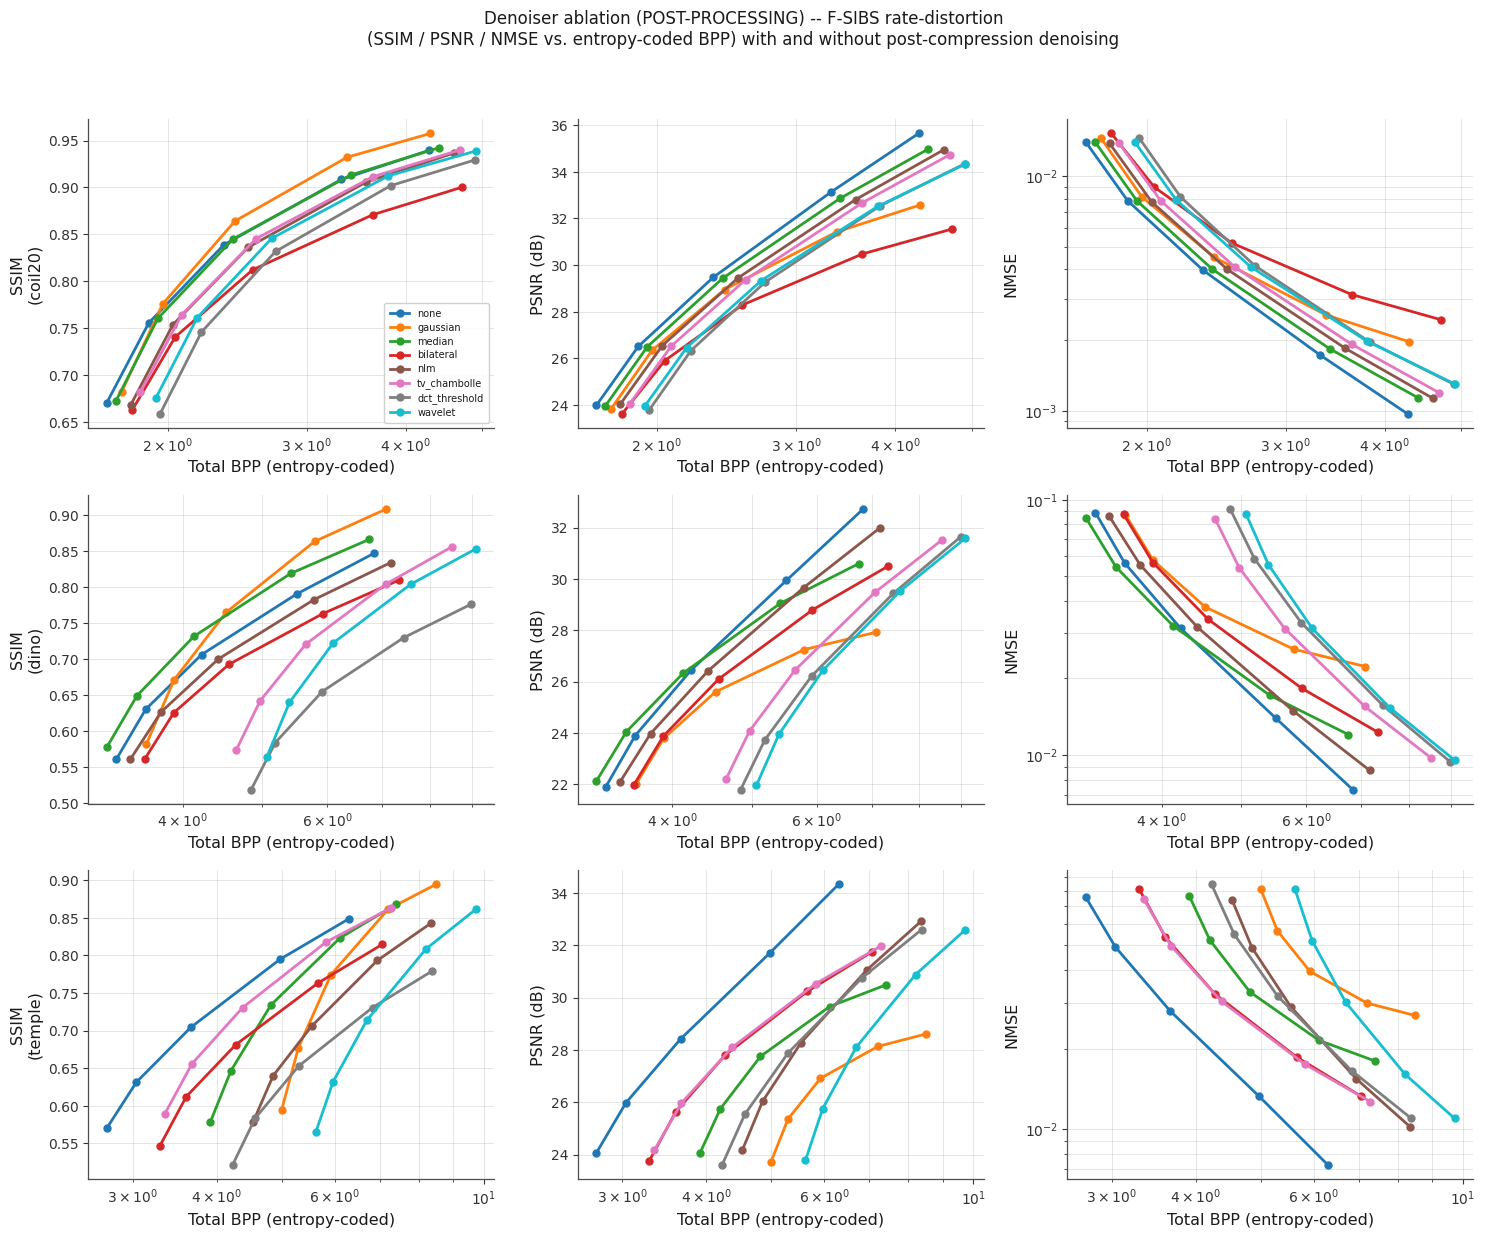

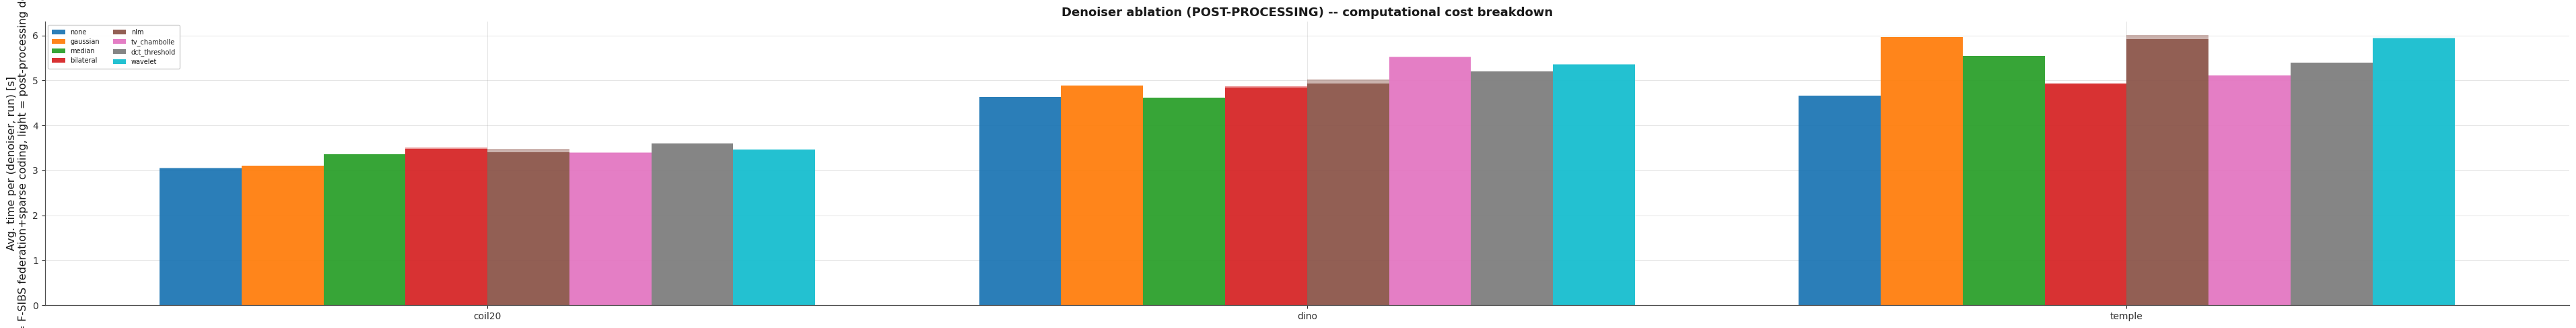

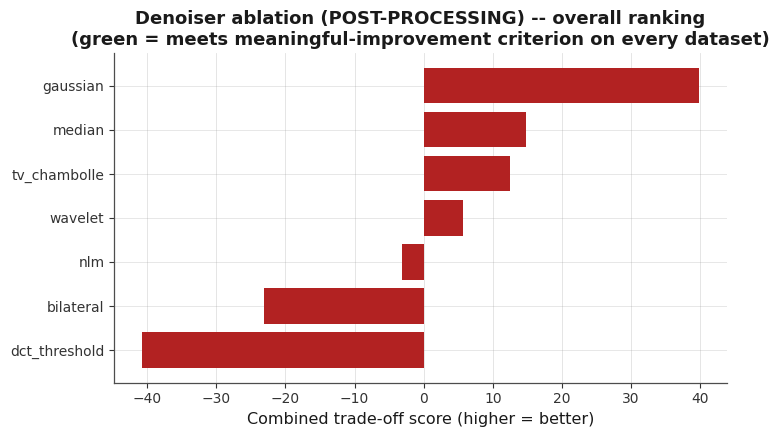


Saved tables: /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_raw_runs.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_rd_curve_by_dataset_denoiser_k.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_summary_by_dataset.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_vs_baseline_per_dataset.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_overall_ranking.csv
Saved figures: /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_rd_curves_ssim_psnr_nmse.png , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_time_breakdown.png , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_overall_ranking.png
E12 self-registered in EXPERIMENT_MANIFEST:

In [7]:
# ============================================================
# EXPERIMENT 12 - Denoiser Ablation (POST-PROCESSING variant).
# Pipeline:
#   1. F-SIBS federation + sparse coding on ORIGINAL images
#   2. For each denoiser: apply denoiser to the RECONSTRUCTION
#      as post-processing to reduce compression artifacts
#   3. Score the enhanced reconstruction against the ORIGINAL
#
# Key property: BPP is identical for all denoisers (the denoiser
# operates AFTER entropy coding), so any quality gain is a pure
# post-processing improvement at fixed bitrate.
# ============================================================

EXP_DENOISE_METHODS = ["none"] + [d for d in EXP_DENOISE_USER_SELECTION
                                  if d in DENOISER_REGISTRY and d != "none"]

print("Denoiser experiment (POST-PROCESSING) -- active denoisers:")
for _d in EXP_DENOISE_METHODS:
    print("  %-14s %s" % (_d, DENOISER_REGISTRY[_d]["params"]))
_skipped_dn = [d for d in EXP_DENOISE_USER_SELECTION if d not in DENOISER_REGISTRY]
if _skipped_dn:
    print("  (skipped, dependency unavailable):", _skipped_dn)

_dn_pick_group = _pick_group

EXP_DENOISE_DATASETS = [ds for ds in SELECTED_DATASETS if ds in POOLS]
EXP_DENOISE_GROUPS = {}
for ds in EXP_DENOISE_DATASETS:
    cfg, g = _dn_pick_group(ds)
    if g is not None:
        EXP_DENOISE_GROUPS[ds] = (cfg, g)

if not EXP_DENOISE_GROUPS:
    print("Skipped: denoiser experiment -- no selected dataset provides a "
          "usable federated node group.")
else:
    _vname_dn, _vfn_dn = next(iter(ACTIVE_F_SIBS_VARIANTS.items()))
    _alg_dn = F_SIBS_VARIANT_TO_SIBS.get(_vname_dn, "SIBS1")
    print("\nDenoiser experiment (POST-PROCESSING) will run on %d dataset(s): %s"
          % (len(EXP_DENOISE_GROUPS),
             ", ".join("%s (%s, group %s, N=%d)"
                       % (ds, cfg, g["group_id"], min(len(g["node_idx"]), EXP_DENOISE_MAX_NODES))
                       for ds, (cfg, g) in EXP_DENOISE_GROUPS.items())))
    print("F-SIBS config reused unchanged: variant=%s (local encoder %s), "
          "DELTA=%d, K_SUMMARY=%d, K_GLOBAL=%d, N_ROUNDS_FULL=%d, tau=%.2f, "
          "K_SWEEP=%s, %d runs/configuration"
          % (_vname_dn, _alg_dn, DELTA, K_SUMMARY, K_GLOBAL, N_ROUNDS_FULL,
             EXP_DENOISE_TAU, EXP_DENOISE_K_SWEEP, EXP_DENOISE_N_RUNS))
    print("NOTE: federation runs on ORIGINAL images; denoiser is applied "
          "AFTER reconstruction as post-processing.")

    _dn_out_dir = os.path.join(FIG_DIR, "denoiser_experiment")
    _dn_results_dir = os.path.join(RESULTS_DIR, "experiment_denoiser")
    os.makedirs(_dn_out_dir, exist_ok=True)
    os.makedirs(_dn_results_dir, exist_ok=True)
    import time as _dn_time
    def _dn_save_table(df, name):
        p1 = os.path.join(_dn_results_dir, name + ".csv")
        p2 = os.path.join(_dn_out_dir, name + ".csv")
        df.to_csv(p1, index=False); df.to_csv(p2, index=False)
        return p1

    def _dn_save_figure(fig, name):
        p1 = os.path.join(_dn_results_dir, name + ".png")
        p2 = os.path.join(_dn_out_dir, name + ".png")
        fig.savefig(p1, dpi=200, bbox_inches="tight")
        fig.savefig(p2, dpi=200, bbox_inches="tight")
        return p1

    # -----------------------------------------------------------
    # STEP 2: main sweep -- unit of work is now (dataset, run),
    #   because federation is shared across all denoisers.
    #   For each (dataset, run):
    #     (a) run federation on ORIGINAL images (once)
    #     (b) for each k, compute and cache reconstructions Xh
    #     (c) for each denoiser, apply denoiser to cached Xh
    #         as post-processing, then score vs. original
    # -----------------------------------------------------------
    EXP_DENOISE_ROWS = []
    _dn_tasks = [(ds, run)
                 for ds in EXP_DENOISE_GROUPS
                 for run in range(EXP_DENOISE_N_RUNS)]

    # ---- CHECKPOINT: key is now (dataset, run) since federation
    # is shared across denoisers. ----
    _dn_checkpoint_path = os.path.join(_dn_out_dir, "denoise_raw_runs.csv")
    _dn_done_keys = set()
    if os.path.exists(_dn_checkpoint_path):
        try:
            _dn_prev = pd.read_csv(_dn_checkpoint_path)
            EXP_DENOISE_ROWS = _dn_prev.to_dict("records")
            # New checkpoint key: (dataset, run)
            _dn_done_keys = set((r["dataset"], int(r["run"]))
                                for r in EXP_DENOISE_ROWS)
            print("Resuming denoiser experiment from checkpoint: %d rows already "
                  "completed for %d (dataset, run) combination(s)."
                  % (len(EXP_DENOISE_ROWS), len(_dn_done_keys)))
        except Exception as _dnck:
            print("Could not read denoiser-experiment checkpoint (%s) -- "
                  "starting fresh." % repr(_dnck))
            EXP_DENOISE_ROWS = []
            _dn_done_keys = set()

    _dn_tasks_remaining = [t for t in _dn_tasks if t not in _dn_done_keys]
    print("%d of %d (dataset, run) combinations remaining after "
          "checkpoint skip." % (len(_dn_tasks_remaining), len(_dn_tasks)))

    def _dn_checkpoint_save():
        _df = pd.DataFrame(EXP_DENOISE_ROWS)
        _df.to_csv(_dn_checkpoint_path, index=False)
        _df.to_csv(os.path.join(_dn_results_dir, "denoise_raw_runs.csv"), index=False)

    for (ds, run) in tqdm(_dn_tasks_remaining, desc="Denoiser experiment sweep",
                          bar_format=PBAR_FORMAT):
        cfg, g = EXP_DENOISE_GROUPS[ds]
        node_idx = g["node_idx"][:EXP_DENOISE_MAX_NODES]
        N_nodes = len(node_idx)
        imgs_orig = [POOLS[ds][i]["img"] for i in node_idx]
        Phi_ds = PHI[ds]
        h, w = GEOMETRY[ds] if ds in GEOMETRY else imgs_orig[0].shape
        n_px = h * w
        seed = 42 + run

        # =============================================================
        # STEP (a): federation on ORIGINAL images (once per (ds, run))
        # =============================================================
        t1 = _dn_time.time()
        try:
            fed = _vfn_dn(imgs_orig, Phi_ds, DELTA, K_SUMMARY, K_global=K_GLOBAL,
                          n_rounds=N_ROUNDS_FULL, tau=EXP_DENOISE_TAU, eps_conv=EPS_CONV,
                          seed=seed, return_transmitted_vectors=True)
        except Exception as _dn_e:
            print("  [ERROR] federation (dataset=%s, run=%d) -> %s: %s"
                  % (ds, run, type(_dn_e).__name__, _dn_e))
            continue

        all_vecs = np.concatenate(
            [v for v in fed["transmitted_vectors_history"] if v.shape[1] > 0], axis=1
        ) if sum(v.shape[1] for v in fed["transmitted_vectors_history"]) > 0 else np.zeros((h, 0))
        if all_vecs.shape[1] > 0:
            q, _ = quantize_coeffs(all_vecs.ravel(), bits=DYNAMIC_SSIM_BITS_COEFF)
            uplink_entropy_bits = float(_entropy_bits_per_symbol(q) * all_vecs.size)
        else:
            uplink_entropy_bits = 0.0
        federated_comm_bpp = uplink_entropy_bits / (N_nodes * n_px)

        Psi_g = fed["global_dict"]
        if Psi_g.shape[1] > 0:
            Phi_aug = np.column_stack([Phi_ds, Psi_g])
            nrm = np.linalg.norm(Phi_aug, axis=0, keepdims=True); nrm[nrm < 1e-12] = 1.0
            Phi_aug = Phi_aug / nrm
        else:
            Phi_aug = Phi_ds
        N_dict = Phi_aug.shape[1]

        fsibs_time_s = _dn_time.time() - t1

        # =============================================================
        # STEP (b): for each k, compute and CACHE reconstructions Xh
        #         (these are shared across all denoisers)
        # =============================================================
        _cached_Xh = {}        # k -> list of Xh arrays (one per node)
        _cached_coef_bpps = {} # k -> mean coefficient BPP
        for k in EXP_DENOISE_K_SWEEP:
            Xh_list = []
            coef_bpps = []
            for X_orig in imgs_orig:
                Xh, K_col, idx, coef = _run_algorithm_generic(
                    _alg_dn, X_orig, Phi_aug, DELTA,
                    lambda xo, et, ph, off, _k=k: _encode_column_fixed(xo, et, ph, off, _k))
                Xh = np.clip(Xh, 0, 255)
                enc = entropy_code_sparse_representation(idx, coef, [k], N_dict,
                                                         bits_coeff=DYNAMIC_SSIM_BITS_COEFF)
                coef_bpps.append(enc["entropy_bits"] / n_px)
                Xh_list.append(Xh)
            _cached_Xh[k] = Xh_list
            _cached_coef_bpps[k] = float(np.mean(coef_bpps))

        # =============================================================
        # STEP (c): for each denoiser, apply as POST-PROCESSING to the
        #           cached reconstructions, then score vs. ORIGINAL
        # =============================================================
        _task_rows = []
        for denoiser in EXP_DENOISE_METHODS:
            denoise_fn = DENOISER_REGISTRY[denoiser]["fn"]
            for k in EXP_DENOISE_K_SWEEP:
                ssims, psnrs, nmses = [], [], []
                t_dn_start = _dn_time.time()
                for X_orig, Xh in zip(imgs_orig, _cached_Xh[k]):
                    # ---- POST-PROCESSING: denoiser applied to reconstruction ----
                    Xh_enhanced = np.clip(denoise_fn(Xh), 0, 255)
                    # ---- score enhanced reconstruction vs. ORIGINAL ----
                    ssims.append(ssim(X_orig, Xh_enhanced))
                    psnrs.append(psnr(X_orig, Xh_enhanced))
                    nmses.append(nmse(X_orig, Xh_enhanced))
                denoise_time_s = _dn_time.time() - t_dn_start

                coef_bpp = _cached_coef_bpps[k]
                total_bpp = coef_bpp + federated_comm_bpp
                _task_rows.append({
                    "dataset": ds, "config": cfg, "group_id": g["group_id"],
                    "denoiser": denoiser, "N_nodes": N_nodes, "run": run, "k": k,
                    "achieved_SSIM": float(np.mean(ssims)),
                    "achieved_PSNR": float(np.mean(psnrs)),
                    "achieved_NMSE": float(np.mean(nmses)),
                    "coefficient_BPP_entropy_coded": coef_bpp,
                    "federated_communication_BPP": federated_comm_bpp,
                    "total_BPP_entropy_coded": total_bpp,
                    "compression_ratio": 8.0 / total_bpp,
                    "denoise_time_s": denoise_time_s,
                    "fsibs_time_s": fsibs_time_s,
                    "total_time_s": fsibs_time_s + denoise_time_s,
                })

        EXP_DENOISE_ROWS.extend(_task_rows)
        _dn_checkpoint_save()

    EXP_DENOISE_RAW_DF = pd.DataFrame(EXP_DENOISE_ROWS)
    _dn_raw_path = _dn_save_table(EXP_DENOISE_RAW_DF, "denoise_raw_runs")

    # -----------------------------------------------------------
    # STEP 3: aggregate over runs
    # -----------------------------------------------------------
    _rd_metric_cols = ["achieved_SSIM", "achieved_PSNR", "achieved_NMSE",
                       "total_BPP_entropy_coded", "compression_ratio"]
    _rd_agg = EXP_DENOISE_RAW_DF.groupby(["dataset", "denoiser", "k"])[_rd_metric_cols].agg(
        ["mean", "std"])
    _rd_agg.columns = ["%s_%s" % (c, s) for c, s in _rd_agg.columns]
    EXP_DENOISE_RD_DF = _rd_agg.reset_index()
    EXP_DENOISE_RD_DF["n_runs"] = EXP_DENOISE_N_RUNS
    _dn_rd_path = _dn_save_table(EXP_DENOISE_RD_DF, "denoise_rd_curve_by_dataset_denoiser_k")

    EXP_DENOISE_SUMMARY_DF = (
        EXP_DENOISE_RAW_DF.groupby(["dataset", "denoiser"])
        .agg(avg_BPP=("total_BPP_entropy_coded", "mean"),
             std_BPP=("total_BPP_entropy_coded", "std"),
             avg_compression_ratio=("compression_ratio", "mean"),
             avg_SSIM=("achieved_SSIM", "mean"), std_SSIM=("achieved_SSIM", "std"),
             avg_PSNR=("achieved_PSNR", "mean"), std_PSNR=("achieved_PSNR", "std"),
             avg_NMSE=("achieved_NMSE", "mean"), std_NMSE=("achieved_NMSE", "std"),
             avg_denoise_time_s=("denoise_time_s", "mean"),
             avg_fsibs_time_s=("fsibs_time_s", "mean"),
             avg_total_time_s=("total_time_s", "mean"),
             n_runs=("run", "nunique"))
        .reset_index())
    _dn_summary_path = _dn_save_table(EXP_DENOISE_SUMMARY_DF, "denoise_summary_by_dataset")

    print("\nDenoiser experiment (POST-PROCESSING) -- summary per (dataset, denoiser), "
          "averaged over K_SWEEP and %d runs:" % EXP_DENOISE_N_RUNS)
    print(EXP_DENOISE_SUMMARY_DF.round(4).to_string(index=False))

    # -----------------------------------------------------------
    # STEP 4: comparison vs. "none" baseline
    # NOTE: BPP is now IDENTICAL for all denoisers (post-processing
    # does not affect bitrate), so the criterion focuses on SSIM
    # GAIN with negligible BPP change.
    # -----------------------------------------------------------
    EXP_DENOISE_MAX_BPP_TOLERANCE_PCT = 1.0     # BPP should not change by more than this %
    EXP_DENOISE_MIN_SSIM_IMPROVEMENT = 0.005    # SSIM must improve by at least this
    EXP_DENOISE_SCORE_W_SSIM_GAIN = 1000.0      # score weight: SSIM improvement
    EXP_DENOISE_SCORE_W_SSIM_LOSS = 1000.0      # score weight: SSIM loss (penalty)
    EXP_DENOISE_SCORE_W_TIME = 0.05             # score weight: % extra compute time

    _cmp_rows = []
    for ds in EXP_DENOISE_GROUPS:
        _s = EXP_DENOISE_SUMMARY_DF[EXP_DENOISE_SUMMARY_DF["dataset"] == ds]
        _base = _s[_s["denoiser"] == "none"]
        if _base.empty:
            continue
        _base = _base.iloc[0]
        for _, row in _s[_s["denoiser"] != "none"].iterrows():
            bpp_change_pct = (row["avg_BPP"] - _base["avg_BPP"]) / _base["avg_BPP"] * 100
            ssim_change = row["avg_SSIM"] - _base["avg_SSIM"]
            psnr_change_db = row["avg_PSNR"] - _base["avg_PSNR"]
            nmse_change_pct = (row["avg_NMSE"] - _base["avg_NMSE"]) / max(_base["avg_NMSE"], 1e-12) * 100
            time_overhead_pct = (row["avg_total_time_s"] - _base["avg_total_time_s"]) / _base["avg_total_time_s"] * 100
            _cmp_rows.append({
                "dataset": ds, "denoiser": row["denoiser"],
                "bpp_change_pct": bpp_change_pct, "ssim_change": ssim_change,
                "psnr_change_db": psnr_change_db, "nmse_change_pct": nmse_change_pct,
                "time_overhead_pct": time_overhead_pct,
                "meaningful_improvement": bool(
                    abs(bpp_change_pct) <= EXP_DENOISE_MAX_BPP_TOLERANCE_PCT and
                    ssim_change >= EXP_DENOISE_MIN_SSIM_IMPROVEMENT),
            })
    EXP_DENOISE_COMPARISON_DF = pd.DataFrame(_cmp_rows)
    _dn_comparison_path = _dn_save_table(EXP_DENOISE_COMPARISON_DF, "denoise_vs_baseline_per_dataset")

    print("\nDenoiser experiment (POST-PROCESSING) -- per-dataset comparison against "
          "the no-denoising baseline (bpp_change_pct should be ~0%% since denoiser "
          "is post-processing; positive ssim_change = quality improvement):")
    print(EXP_DENOISE_COMPARISON_DF.round(4).to_string(index=False))

    # ---- overall ranking ----
    EXP_DENOISE_OVERALL_DF = (
        EXP_DENOISE_COMPARISON_DF.groupby("denoiser")
        .agg(mean_bpp_change_pct=("bpp_change_pct", "mean"),
             mean_ssim_change=("ssim_change", "mean"),
             mean_psnr_change_db=("psnr_change_db", "mean"),
             mean_nmse_change_pct=("nmse_change_pct", "mean"),
             mean_time_overhead_pct=("time_overhead_pct", "mean"),
             meaningful_improvement_on_n_datasets=("meaningful_improvement", "sum"),
             n_datasets=("dataset", "nunique"))
        .reset_index())
    # Score: reward SSIM gain, penalize SSIM loss and time overhead
    EXP_DENOISE_OVERALL_DF["score"] = (
        EXP_DENOISE_OVERALL_DF["mean_ssim_change"] * EXP_DENOISE_SCORE_W_SSIM_GAIN
        - EXP_DENOISE_OVERALL_DF["mean_time_overhead_pct"] * EXP_DENOISE_SCORE_W_TIME)
    EXP_DENOISE_OVERALL_DF["meaningful_improvement_overall"] = (
        EXP_DENOISE_OVERALL_DF["meaningful_improvement_on_n_datasets"]
        == EXP_DENOISE_OVERALL_DF["n_datasets"])
    EXP_DENOISE_OVERALL_DF = EXP_DENOISE_OVERALL_DF.sort_values("score", ascending=False)
    _dn_overall_path = _dn_save_table(EXP_DENOISE_OVERALL_DF, "denoise_overall_ranking")

    print("\nDenoiser experiment (POST-PROCESSING) -- OVERALL ranking (averaged across "
          "all %d selected dataset(s); score = %.0f*mean_ssim_change "
          "- %.2f*mean_time_overhead_pct; higher = better trade-off):"
          % (len(EXP_DENOISE_GROUPS), EXP_DENOISE_SCORE_W_SSIM_GAIN,
             EXP_DENOISE_SCORE_W_TIME))
    print(EXP_DENOISE_OVERALL_DF.round(4).to_string(index=False))

    _meaningful = EXP_DENOISE_OVERALL_DF[EXP_DENOISE_OVERALL_DF["meaningful_improvement_overall"]]
    if not _meaningful.empty:
        _best = _meaningful.iloc[0]
        print("\n==> BEST post-processing denoiser for F-SIBS: "
              "'%s' -- avg SSIM change %+.4f, avg PSNR change %+.3f dB, "
              "avg time overhead %.1f%%, meets the meaningful-improvement "
              "criterion (|BPP change| <= %.1f%%, SSIM gain >= %.3f) on %d/%d dataset(s)."
              % (_best["denoiser"], _best["mean_ssim_change"], _best["mean_psnr_change_db"],
                 _best["mean_time_overhead_pct"], EXP_DENOISE_MAX_BPP_TOLERANCE_PCT,
                 EXP_DENOISE_MIN_SSIM_IMPROVEMENT,
                 _best["meaningful_improvement_on_n_datasets"], _best["n_datasets"]))
    else:
        _best_overall = EXP_DENOISE_OVERALL_DF.iloc[0] if len(EXP_DENOISE_OVERALL_DF) else None
        print("\n==> No denoiser met the meaningful-improvement criterion "
              "(|BPP change| <= %.1f%% together with SSIM gain >= %.3f) on "
              "every selected dataset -- post-processing denoising as tested "
              "here does not reliably improve reconstruction quality."
              % (EXP_DENOISE_MAX_BPP_TOLERANCE_PCT, EXP_DENOISE_MIN_SSIM_IMPROVEMENT))
        if _best_overall is not None:
            print("    Closest / least-bad option by the combined score: '%s' "
                  "(avg SSIM change %+.4f, avg time overhead %.1f%%)."
                  % (_best_overall["denoiser"], _best_overall["mean_ssim_change"],
                     _best_overall["mean_time_overhead_pct"]))

    # -----------------------------------------------------------
    # STEP 5: figures
    # -----------------------------------------------------------
    _dn_datasets_plotted = list(EXP_DENOISE_GROUPS.keys())
    _n_ds = len(_dn_datasets_plotted)
    _dn_colors = plt.cm.tab10(np.linspace(0, 0.9, len(EXP_DENOISE_METHODS)))
    _dn_color_map = dict(zip(EXP_DENOISE_METHODS, _dn_colors))

    # ---- Fig 1: SSIM / PSNR / NMSE vs. entropy-coded BPP ----
    # NOTE: all denoisers share the same BPP points; curves differ only in quality.
    # We add small horizontal jitter for visual separation.
    fig, axes = plt.subplots(_n_ds, 3, figsize=(15, 4.2 * _n_ds), squeeze=False)
    for _i, ds in enumerate(_dn_datasets_plotted):
        _sub = EXP_DENOISE_RD_DF[EXP_DENOISE_RD_DF["dataset"] == ds]
        _dn_list = list(EXP_DENOISE_METHODS)
        for _j, denoiser in enumerate(_dn_list):
            _curve = _sub[_sub["denoiser"] == denoiser].sort_values("total_BPP_entropy_coded_mean")
            if _curve.empty:
                continue
            # small jitter so overlapping points are visible
            _jitter = (_j - len(_dn_list) / 2) * 0.015
            _bpp = _curve["total_BPP_entropy_coded_mean"].values * (1 + _jitter)
            _kw = dict(color=_dn_color_map[denoiser], marker="o", lw=2, markersize=5,
                       label=denoiser)
            axes[_i][0].plot(_bpp, _curve["achieved_SSIM_mean"].values, **_kw)
            axes[_i][1].plot(_bpp, _curve["achieved_PSNR_mean"].values, **_kw)
            axes[_i][2].plot(_bpp, _curve["achieved_NMSE_mean"].values, **_kw)
        axes[_i][0].set_ylabel("SSIM\n(%s)" % ds); axes[_i][1].set_ylabel("PSNR (dB)")
        axes[_i][2].set_ylabel("NMSE")
        for _ax in axes[_i]:
            _ax.set_xlabel("Total BPP (entropy-coded)"); _ax.set_xscale("log")
            _ax.grid(True, which="both", alpha=0.3)
        axes[_i][2].set_yscale("log")
    axes[0][0].legend(fontsize=7, loc="lower right")
    fig.suptitle("Denoiser ablation (POST-PROCESSING) -- F-SIBS rate-distortion\n"
                 "(SSIM / PSNR / NMSE vs. entropy-coded BPP) with and without "
                 "post-compression denoising",
                 fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    _dn_fig1_path = _dn_save_figure(fig, "denoise_rd_curves_ssim_psnr_nmse")
    plt.show()

    # ---- Fig 2: execution time breakdown (F-SIBS vs. post-processing denoise) ----
    _time_piv_dn = EXP_DENOISE_SUMMARY_DF.pivot(index="dataset", columns="denoiser",
                                                values="avg_denoise_time_s").reindex(
        columns=EXP_DENOISE_METHODS)
    _time_piv_fs = EXP_DENOISE_SUMMARY_DF.pivot(index="dataset", columns="denoiser",
                                                values="avg_fsibs_time_s").reindex(
        columns=EXP_DENOISE_METHODS)
    fig2, ax2 = plt.subplots(figsize=(max(7, 1.6 * len(EXP_DENOISE_METHODS) * _n_ds), 5))
    _x = np.arange(_n_ds); _bw = 0.8 / len(EXP_DENOISE_METHODS)
    for _j, denoiser in enumerate(EXP_DENOISE_METHODS):
        _xs = _x + _j * _bw - 0.4 + _bw / 2
        _ftime = _time_piv_fs[denoiser].values  # F-SIBS (bottom, shared)
        _dtime = _time_piv_dn[denoiser].values  # denoise (top, per-denoiser)
        ax2.bar(_xs, _ftime, width=_bw, color=_dn_color_map[denoiser], alpha=0.95,
                label=denoiser)
        ax2.bar(_xs, _dtime, width=_bw, bottom=_ftime, color=_dn_color_map[denoiser],
                alpha=0.45)
    ax2.set_xticks(_x); ax2.set_xticklabels(_dn_datasets_plotted)
    ax2.set_ylabel("Avg. time per (denoiser, run) [s]\n"
                   "(solid = F-SIBS federation+sparse coding, "
                   "light = post-processing denoise)")
    ax2.set_title("Denoiser ablation (POST-PROCESSING) -- computational cost breakdown")
    ax2.legend(fontsize=7, ncol=2); ax2.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    _dn_fig2_path = _dn_save_figure(fig2, "denoise_time_breakdown")
    plt.show()

    # ---- Fig 3: overall combined score per denoiser ----
    fig3, ax3 = plt.subplots(figsize=(7.5, 4.5))
    _ov = EXP_DENOISE_OVERALL_DF.sort_values("score")
    _bar_colors = ["#2ca02c" if m else "#b22222" for m in _ov["meaningful_improvement_overall"]]
    ax3.barh(_ov["denoiser"], _ov["score"], color=_bar_colors)
    ax3.set_xlabel("Combined trade-off score (higher = better)")
    ax3.set_title("Denoiser ablation (POST-PROCESSING) -- overall ranking\n"
                  "(green = meets meaningful-improvement criterion on every dataset)")
    ax3.grid(True, axis="x", alpha=0.3)
    plt.tight_layout()
    _dn_fig3_path = _dn_save_figure(fig3, "denoise_overall_ranking")
    plt.show()

    print("\nSaved tables:", _dn_raw_path, ",", _dn_rd_path, ",", _dn_summary_path,
          ",", _dn_comparison_path, ",", _dn_overall_path)
    print("Saved figures:", _dn_fig1_path, ",", _dn_fig2_path, ",", _dn_fig3_path)

# ---- E12 manifest self-registration ----
for _dn_name in ["denoise_raw_runs", "denoise_rd_curve_by_dataset_denoiser_k",
                 "denoise_summary_by_dataset", "denoise_vs_baseline_per_dataset",
                 "denoise_overall_ranking"]:
    for _dn_dir in [os.path.join(RESULTS_DIR, "experiment_denoiser"),
                    os.path.join(FIG_DIR, "denoiser_experiment")]:
        if os.path.exists(os.path.join(_dn_dir, _dn_name + ".csv")):
            if _dn_name + ".csv" not in EXPERIMENT_MANIFEST[12]["tables"]:
                EXPERIMENT_MANIFEST[12]["tables"].append(_dn_name + ".csv")
            break
for _dn_name in ["denoise_rd_curves_ssim_psnr_nmse", "denoise_time_breakdown",
                 "denoise_overall_ranking"]:
    for _dn_dir in [os.path.join(RESULTS_DIR, "experiment_denoiser"),
                    os.path.join(FIG_DIR, "denoiser_experiment")]:
        if os.path.exists(os.path.join(_dn_dir, _dn_name + ".png")):
            if _dn_name + ".png" not in EXPERIMENT_MANIFEST[12]["figures"]:
                EXPERIMENT_MANIFEST[12]["figures"].append(_dn_name + ".png")
            break
print("E12 self-registered in EXPERIMENT_MANIFEST: %d table(s), %d figure(s)"
      % (len(EXPERIMENT_MANIFEST[12]["tables"]), len(EXPERIMENT_MANIFEST[12]["figures"])))

Denoiser experiment (POST-PROCESSING) -- active denoisers:
  none           {}
  gaussian       {'sigma': 1.0}
  median         {'size': 3}
  bilateral      {'sigma_color': 0.05, 'sigma_spatial': 1.0}
  nlm            {'h': 10.0, 'patch_size': 5, 'patch_distance': 6}
  tv_chambolle   {'weight': 10.0}
  dct_threshold  {'threshold': 12.0}
  wavelet        {'wavelet': 'db2', 'level': 2, 'threshold': 10.0, 'mode': 'soft'}

Denoiser experiment (POST-PROCESSING) will run on 4 dataset(s): coil20 (coil20_same_object, group coil20_obj01, N=4), dino (dino_ring, group dino_ring, N=6), temple (temple_ring, group temple_ring, N=6), coil100 (coil100_cross_object, group coil100_xobj_g1, N=4)
F-SIBS config reused unchanged: variant=F-SIBS_1 (local encoder SIBS1), DELTA=8, K_SUMMARY=8, K_GLOBAL=16, N_ROUNDS_FULL=8, tau=0.95, K_SWEEP=[2, 4, 8, 16, 24], 3 runs/configuration
NOTE: federation runs on ORIGINAL images; denoiser is applied AFTER reconstruction as post-processing.
Removed old checkpoint file t

Denoiser experiment sweep: 100% complete |██████████| 12/12 [00:56<00:00]



Denoiser experiment (POST-PROCESSING) -- summary per (dataset, denoiser), averaged over K_SWEEP and 3 runs:
dataset      denoiser  avg_BPP  std_BPP  avg_compression_ratio  avg_SSIM  std_SSIM  avg_PSNR  std_PSNR  avg_NMSE  std_NMSE  avg_denoise_time_s  avg_fsibs_time_s  avg_total_time_s  n_runs
coil100     bilateral   2.9818   1.1457                 3.0513    0.8689    0.0661   30.7337    2.7651    0.0116    0.0074              0.0270            1.2759            1.3029       3
coil100 dct_threshold   2.9818   1.1457                 3.0513    0.8135    0.0873   31.6924    3.3543    0.0107    0.0073              0.0063            1.2759            1.2822       3
coil100      gaussian   2.9818   1.1457                 3.0513    0.8733    0.0700   31.5806    2.7640    0.0108    0.0059              0.0060            1.2759            1.2819       3
coil100        median   2.9818   1.1457                 3.0513    0.8623    0.0803   32.4672    3.6990    0.0099    0.0067              0.0128 

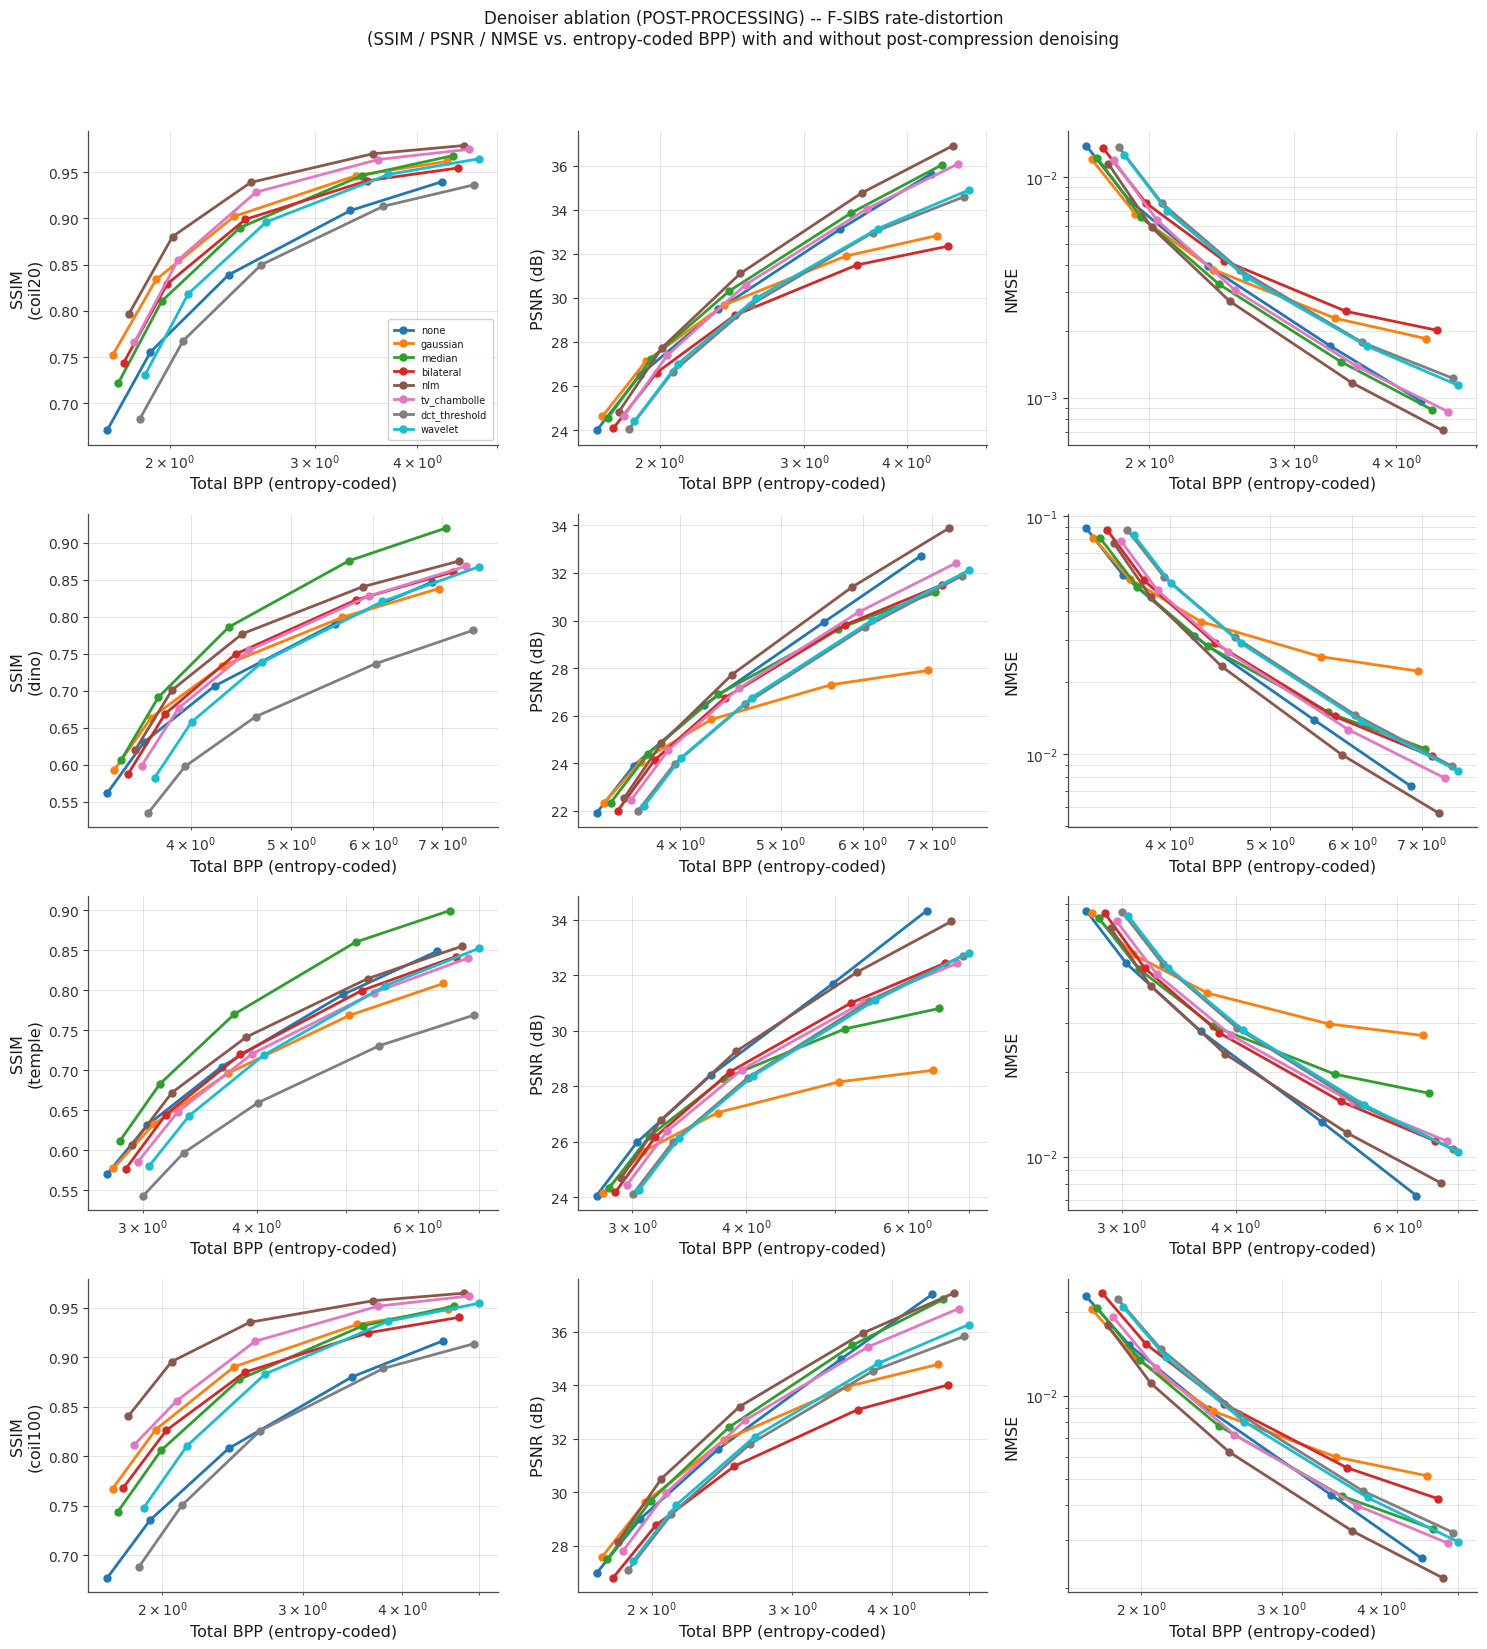

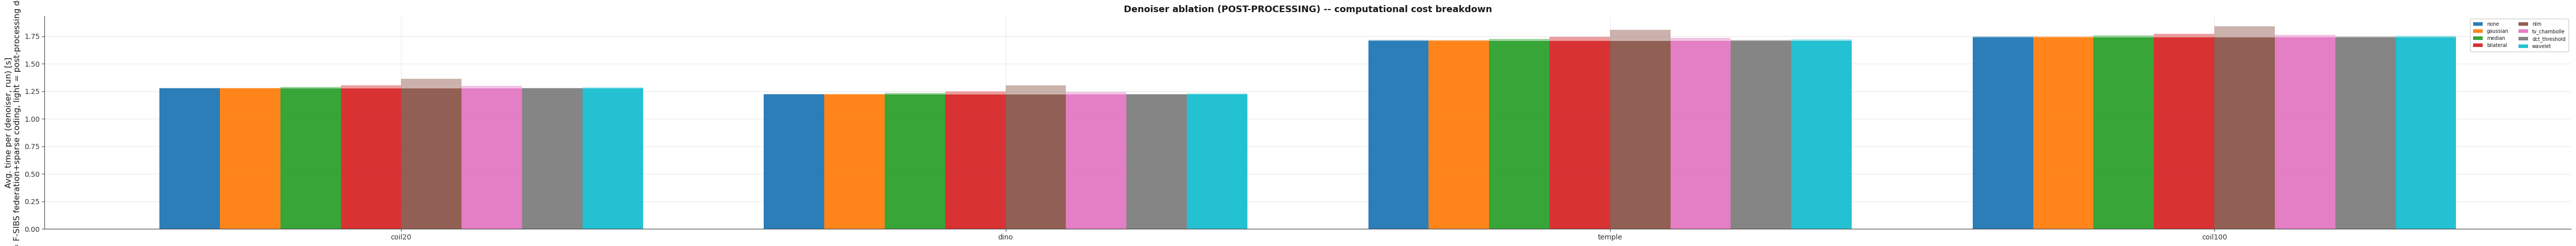

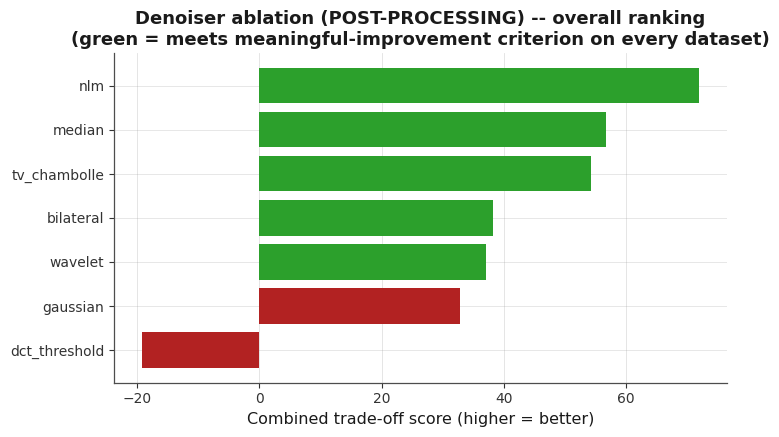


Saved tables: /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_raw_runs.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_rd_curve_by_dataset_denoiser_k.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_summary_by_dataset.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_vs_baseline_per_dataset.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_overall_ranking.csv
Saved figures: /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_rd_curves_ssim_psnr_nmse.png , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_time_breakdown.png , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_overall_ranking.png
E12 self-registered in EXPERIMENT_MANIFEST:

In [16]:
# ============================================================
# EXPERIMENT 12 - Denoiser Ablation (POST-PROCESSING variant).
# Pipeline:
#   1. F-SIBS federation + sparse coding on ORIGINAL images
#   2. For each denoiser: apply denoiser to the RECONSTRUCTION
#      as post-processing to reduce compression artifacts
#   3. Score the enhanced reconstruction against the ORIGINAL
#
# Key property: BPP is identical for all denoisers (the denoiser
# operates AFTER entropy coding), so any quality gain is a pure
# post-processing improvement at fixed bitrate.
# ============================================================

EXP_DENOISE_METHODS = ["none"] + [d for d in EXP_DENOISE_USER_SELECTION
                                  if d in DENOISER_REGISTRY and d != "none"]

print("Denoiser experiment (POST-PROCESSING) -- active denoisers:")
for _d in EXP_DENOISE_METHODS:
    print("  %-14s %s" % (_d, DENOISER_REGISTRY[_d]["params"]))
_skipped_dn = [d for d in EXP_DENOISE_USER_SELECTION if d not in DENOISER_REGISTRY]
if _skipped_dn:
    print("  (skipped, dependency unavailable):", _skipped_dn)

_dn_pick_group = _pick_group

EXP_DENOISE_DATASETS = [ds for ds in SELECTED_DATASETS if ds in POOLS]
EXP_DENOISE_GROUPS = {}
for ds in EXP_DENOISE_DATASETS:
    cfg, g = _dn_pick_group(ds)
    if g is not None:
        EXP_DENOISE_GROUPS[ds] = (cfg, g)

if not EXP_DENOISE_GROUPS:
    print("Skipped: denoiser experiment -- no selected dataset provides a "
          "usable federated node group.")
else:
    _vname_dn, _vfn_dn = next(iter(ACTIVE_F_SIBS_VARIANTS.items()))
    _alg_dn = F_SIBS_VARIANT_TO_SIBS.get(_vname_dn, "SIBS1")
    print("\nDenoiser experiment (POST-PROCESSING) will run on %d dataset(s): %s"
          % (len(EXP_DENOISE_GROUPS),
             ", ".join("%s (%s, group %s, N=%d)"
                       % (ds, cfg, g["group_id"], min(len(g["node_idx"]), EXP_DENOISE_MAX_NODES))
                       for ds, (cfg, g) in EXP_DENOISE_GROUPS.items())))
    print("F-SIBS config reused unchanged: variant=%s (local encoder %s), "
          "DELTA=%d, K_SUMMARY=%d, K_GLOBAL=%d, N_ROUNDS_FULL=%d, tau=%.2f, "
          "K_SWEEP=%s, %d runs/configuration"
          % (_vname_dn, _alg_dn, DELTA, K_SUMMARY, K_GLOBAL, N_ROUNDS_FULL,
             EXP_DENOISE_TAU, EXP_DENOISE_K_SWEEP, EXP_DENOISE_N_RUNS))
    print("NOTE: federation runs on ORIGINAL images; denoiser is applied "
          "AFTER reconstruction as post-processing.")

    _dn_out_dir = os.path.join(FIG_DIR, "denoiser_experiment")
    _dn_results_dir = os.path.join(RESULTS_DIR, "experiment_denoiser")
    os.makedirs(_dn_out_dir, exist_ok=True)
    os.makedirs(_dn_results_dir, exist_ok=True)
    import time as _dn_time
    def _dn_save_table(df, name):
        p1 = os.path.join(_dn_results_dir, name + ".csv")
        p2 = os.path.join(_dn_out_dir, name + ".csv")
        df.to_csv(p1, index=False); df.to_csv(p2, index=False)
        return p1

    def _dn_save_figure(fig, name):
        p1 = os.path.join(_dn_results_dir, name + ".png")
        p2 = os.path.join(_dn_out_dir, name + ".png")
        fig.savefig(p1, dpi=200, bbox_inches="tight")
        fig.savefig(p2, dpi=200, bbox_inches="tight")
        return p1

    # -----------------------------------------------------------
    # STEP 2: main sweep -- unit of work is now (dataset, run),
    #   because federation is shared across all denoisers.
    #   For each (dataset, run):
    #     (a) run federation on ORIGINAL images (once)
    #     (b) for each k, compute and cache reconstructions Xh
    #     (c) for each denoiser, apply denoiser to cached Xh
    #         as post-processing, then score vs. original
    # -----------------------------------------------------------
    EXP_DENOISE_ROWS = []
    _dn_tasks = [(ds, run)
                 for ds in EXP_DENOISE_GROUPS
                 for run in range(EXP_DENOISE_N_RUNS)]

    # ---- CHECKPOINT DISABLED: Force re-run of all combinations ----
    _dn_checkpoint_path = os.path.join(_dn_out_dir, "denoise_raw_runs.csv")
    if os.path.exists(_dn_checkpoint_path):
        os.remove(_dn_checkpoint_path)
        print("Removed old checkpoint file to force complete re-run.")
    
    _dn_done_keys = set()
    _dn_tasks_remaining = _dn_tasks
    print("Running all %d (dataset, run) combinations from scratch." 
          % len(_dn_tasks))

    def _dn_checkpoint_save():
        _df = pd.DataFrame(EXP_DENOISE_ROWS)
        _df.to_csv(_dn_checkpoint_path, index=False)
        _df.to_csv(os.path.join(_dn_results_dir, "denoise_raw_runs.csv"), index=False)

    for (ds, run) in tqdm(_dn_tasks_remaining, desc="Denoiser experiment sweep",
                          bar_format=PBAR_FORMAT):
        cfg, g = EXP_DENOISE_GROUPS[ds]
        node_idx = g["node_idx"][:EXP_DENOISE_MAX_NODES]
        N_nodes = len(node_idx)
        imgs_orig = [POOLS[ds][i]["img"] for i in node_idx]
        Phi_ds = PHI[ds]
        h, w = GEOMETRY[ds] if ds in GEOMETRY else imgs_orig[0].shape
        n_px = h * w
        seed = 42 + run

        # =============================================================
        # STEP (a): federation on ORIGINAL images (once per (ds, run))
        # =============================================================
        t1 = _dn_time.time()
        try:
            fed = _vfn_dn(imgs_orig, Phi_ds, DELTA, K_SUMMARY, K_global=K_GLOBAL,
                          n_rounds=N_ROUNDS_FULL, tau=EXP_DENOISE_TAU, eps_conv=EPS_CONV,
                          seed=seed, return_transmitted_vectors=True)
        except Exception as _dn_e:
            print("  [ERROR] federation (dataset=%s, run=%d) -> %s: %s"
                  % (ds, run, type(_dn_e).__name__, _dn_e))
            continue

        all_vecs = np.concatenate(
            [v for v in fed["transmitted_vectors_history"] if v.shape[1] > 0], axis=1
        ) if sum(v.shape[1] for v in fed["transmitted_vectors_history"]) > 0 else np.zeros((h, 0))
        if all_vecs.shape[1] > 0:
            q, _ = quantize_coeffs(all_vecs.ravel(), bits=DYNAMIC_SSIM_BITS_COEFF)
            uplink_entropy_bits = float(_entropy_bits_per_symbol(q) * all_vecs.size)
        else:
            uplink_entropy_bits = 0.0
        federated_comm_bpp = uplink_entropy_bits / (N_nodes * n_px)

        Psi_g = fed["global_dict"]
        if Psi_g.shape[1] > 0:
            Phi_aug = np.column_stack([Phi_ds, Psi_g])
            nrm = np.linalg.norm(Phi_aug, axis=0, keepdims=True); nrm[nrm < 1e-12] = 1.0
            Phi_aug = Phi_aug / nrm
        else:
            Phi_aug = Phi_ds
        N_dict = Phi_aug.shape[1]

        fsibs_time_s = _dn_time.time() - t1

        # =============================================================
        # STEP (b): for each k, compute and CACHE reconstructions Xh
        #         (these are shared across all denoisers)
        # =============================================================
        _cached_Xh = {}        # k -> list of Xh arrays (one per node)
        _cached_coef_bpps = {} # k -> mean coefficient BPP
        for k in EXP_DENOISE_K_SWEEP:
            Xh_list = []
            coef_bpps = []
            for X_orig in imgs_orig:
                Xh, K_col, idx, coef = _run_algorithm_generic(
                    _alg_dn, X_orig, Phi_aug, DELTA,
                    lambda xo, et, ph, off, _k=k: _encode_column_fixed(xo, et, ph, off, _k))
                Xh = np.clip(Xh, 0, 255)
                enc = entropy_code_sparse_representation(idx, coef, [k], N_dict,
                                                         bits_coeff=DYNAMIC_SSIM_BITS_COEFF)
                coef_bpps.append(enc["entropy_bits"] / n_px)
                Xh_list.append(Xh)
            _cached_Xh[k] = Xh_list
            _cached_coef_bpps[k] = float(np.mean(coef_bpps))

        # =============================================================
        # STEP (c): for each denoiser, apply as POST-PROCESSING to the
        #           cached reconstructions, then score vs. ORIGINAL
        # =============================================================
        _task_rows = []
        for denoiser in EXP_DENOISE_METHODS:
            denoise_fn = DENOISER_REGISTRY[denoiser]["fn"]
            for k in EXP_DENOISE_K_SWEEP:
                ssims, psnrs, nmses = [], [], []
                t_dn_start = _dn_time.time()
                for X_orig, Xh in zip(imgs_orig, _cached_Xh[k]):
                    # ---- POST-PROCESSING: denoiser applied to reconstruction ----
                    Xh_enhanced = np.clip(denoise_fn(Xh), 0, 255)
                    # ---- score enhanced reconstruction vs. ORIGINAL ----
                    ssims.append(ssim(X_orig, Xh_enhanced))
                    psnrs.append(psnr(X_orig, Xh_enhanced))
                    nmses.append(nmse(X_orig, Xh_enhanced))
                denoise_time_s = _dn_time.time() - t_dn_start

                coef_bpp = _cached_coef_bpps[k]
                total_bpp = coef_bpp + federated_comm_bpp
                _task_rows.append({
                    "dataset": ds, "config": cfg, "group_id": g["group_id"],
                    "denoiser": denoiser, "N_nodes": N_nodes, "run": run, "k": k,
                    "achieved_SSIM": float(np.mean(ssims)),
                    "achieved_PSNR": float(np.mean(psnrs)),
                    "achieved_NMSE": float(np.mean(nmses)),
                    "coefficient_BPP_entropy_coded": coef_bpp,
                    "federated_communication_BPP": federated_comm_bpp,
                    "total_BPP_entropy_coded": total_bpp,
                    "compression_ratio": 8.0 / total_bpp,
                    "denoise_time_s": denoise_time_s,
                    "fsibs_time_s": fsibs_time_s,
                    "total_time_s": fsibs_time_s + denoise_time_s,
                })

        EXP_DENOISE_ROWS.extend(_task_rows)
        _dn_checkpoint_save()

    EXP_DENOISE_RAW_DF = pd.DataFrame(EXP_DENOISE_ROWS)
    _dn_raw_path = _dn_save_table(EXP_DENOISE_RAW_DF, "denoise_raw_runs")

    # -----------------------------------------------------------
    # STEP 3: aggregate over runs
    # -----------------------------------------------------------
    _rd_metric_cols = ["achieved_SSIM", "achieved_PSNR", "achieved_NMSE",
                       "total_BPP_entropy_coded", "compression_ratio"]
    _rd_agg = EXP_DENOISE_RAW_DF.groupby(["dataset", "denoiser", "k"])[_rd_metric_cols].agg(
        ["mean", "std"])
    _rd_agg.columns = ["%s_%s" % (c, s) for c, s in _rd_agg.columns]
    EXP_DENOISE_RD_DF = _rd_agg.reset_index()
    EXP_DENOISE_RD_DF["n_runs"] = EXP_DENOISE_N_RUNS
    _dn_rd_path = _dn_save_table(EXP_DENOISE_RD_DF, "denoise_rd_curve_by_dataset_denoiser_k")

    EXP_DENOISE_SUMMARY_DF = (
        EXP_DENOISE_RAW_DF.groupby(["dataset", "denoiser"])
        .agg(avg_BPP=("total_BPP_entropy_coded", "mean"),
             std_BPP=("total_BPP_entropy_coded", "std"),
             avg_compression_ratio=("compression_ratio", "mean"),
             avg_SSIM=("achieved_SSIM", "mean"), std_SSIM=("achieved_SSIM", "std"),
             avg_PSNR=("achieved_PSNR", "mean"), std_PSNR=("achieved_PSNR", "std"),
             avg_NMSE=("achieved_NMSE", "mean"), std_NMSE=("achieved_NMSE", "std"),
             avg_denoise_time_s=("denoise_time_s", "mean"),
             avg_fsibs_time_s=("fsibs_time_s", "mean"),
             avg_total_time_s=("total_time_s", "mean"),
             n_runs=("run", "nunique"))
        .reset_index())
    _dn_summary_path = _dn_save_table(EXP_DENOISE_SUMMARY_DF, "denoise_summary_by_dataset")

    print("\nDenoiser experiment (POST-PROCESSING) -- summary per (dataset, denoiser), "
          "averaged over K_SWEEP and %d runs:" % EXP_DENOISE_N_RUNS)
    print(EXP_DENOISE_SUMMARY_DF.round(4).to_string(index=False))

    # -----------------------------------------------------------
    # STEP 4: comparison vs. "none" baseline
    # NOTE: BPP is now IDENTICAL for all denoisers (post-processing
    # does not affect bitrate), so the criterion focuses on SSIM
    # GAIN with negligible BPP change.
    # -----------------------------------------------------------
    EXP_DENOISE_MAX_BPP_TOLERANCE_PCT = 1.0     # BPP should not change by more than this %
    EXP_DENOISE_MIN_SSIM_IMPROVEMENT = 0.005    # SSIM must improve by at least this
    EXP_DENOISE_SCORE_W_SSIM_GAIN = 1000.0      # score weight: SSIM improvement
    EXP_DENOISE_SCORE_W_SSIM_LOSS = 1000.0      # score weight: SSIM loss (penalty)
    EXP_DENOISE_SCORE_W_TIME = 0.05             # score weight: % extra compute time

    _cmp_rows = []
    for ds in EXP_DENOISE_GROUPS:
        _s = EXP_DENOISE_SUMMARY_DF[EXP_DENOISE_SUMMARY_DF["dataset"] == ds]
        _base = _s[_s["denoiser"] == "none"]
        if _base.empty:
            continue
        _base = _base.iloc[0]
        for _, row in _s[_s["denoiser"] != "none"].iterrows():
            bpp_change_pct = (row["avg_BPP"] - _base["avg_BPP"]) / _base["avg_BPP"] * 100
            ssim_change = row["avg_SSIM"] - _base["avg_SSIM"]
            psnr_change_db = row["avg_PSNR"] - _base["avg_PSNR"]
            nmse_change_pct = (row["avg_NMSE"] - _base["avg_NMSE"]) / max(_base["avg_NMSE"], 1e-12) * 100
            time_overhead_pct = (row["avg_total_time_s"] - _base["avg_total_time_s"]) / _base["avg_total_time_s"] * 100
            _cmp_rows.append({
                "dataset": ds, "denoiser": row["denoiser"],
                "bpp_change_pct": bpp_change_pct, "ssim_change": ssim_change,
                "psnr_change_db": psnr_change_db, "nmse_change_pct": nmse_change_pct,
                "time_overhead_pct": time_overhead_pct,
                "meaningful_improvement": bool(
                    abs(bpp_change_pct) <= EXP_DENOISE_MAX_BPP_TOLERANCE_PCT and
                    ssim_change >= EXP_DENOISE_MIN_SSIM_IMPROVEMENT),
            })
    EXP_DENOISE_COMPARISON_DF = pd.DataFrame(_cmp_rows)
    _dn_comparison_path = _dn_save_table(EXP_DENOISE_COMPARISON_DF, "denoise_vs_baseline_per_dataset")

    print("\nDenoiser experiment (POST-PROCESSING) -- per-dataset comparison against "
          "the no-denoising baseline (bpp_change_pct should be ~0%% since denoiser "
          "is post-processing; positive ssim_change = quality improvement):")
    print(EXP_DENOISE_COMPARISON_DF.round(4).to_string(index=False))

    # ---- overall ranking ----
    EXP_DENOISE_OVERALL_DF = (
        EXP_DENOISE_COMPARISON_DF.groupby("denoiser")
        .agg(mean_bpp_change_pct=("bpp_change_pct", "mean"),
             mean_ssim_change=("ssim_change", "mean"),
             mean_psnr_change_db=("psnr_change_db", "mean"),
             mean_nmse_change_pct=("nmse_change_pct", "mean"),
             mean_time_overhead_pct=("time_overhead_pct", "mean"),
             meaningful_improvement_on_n_datasets=("meaningful_improvement", "sum"),
             n_datasets=("dataset", "nunique"))
        .reset_index())
    # Score: reward SSIM gain, penalize SSIM loss and time overhead
    EXP_DENOISE_OVERALL_DF["score"] = (
        EXP_DENOISE_OVERALL_DF["mean_ssim_change"] * EXP_DENOISE_SCORE_W_SSIM_GAIN
        - EXP_DENOISE_OVERALL_DF["mean_time_overhead_pct"] * EXP_DENOISE_SCORE_W_TIME)
    EXP_DENOISE_OVERALL_DF["meaningful_improvement_overall"] = (
        EXP_DENOISE_OVERALL_DF["meaningful_improvement_on_n_datasets"]
        == EXP_DENOISE_OVERALL_DF["n_datasets"])
    EXP_DENOISE_OVERALL_DF = EXP_DENOISE_OVERALL_DF.sort_values("score", ascending=False)
    _dn_overall_path = _dn_save_table(EXP_DENOISE_OVERALL_DF, "denoise_overall_ranking")

    print("\nDenoiser experiment (POST-PROCESSING) -- OVERALL ranking (averaged across "
          "all %d selected dataset(s); score = %.0f*mean_ssim_change "
          "- %.2f*mean_time_overhead_pct; higher = better trade-off):"
          % (len(EXP_DENOISE_GROUPS), EXP_DENOISE_SCORE_W_SSIM_GAIN,
             EXP_DENOISE_SCORE_W_TIME))
    print(EXP_DENOISE_OVERALL_DF.round(4).to_string(index=False))

    _meaningful = EXP_DENOISE_OVERALL_DF[EXP_DENOISE_OVERALL_DF["meaningful_improvement_overall"]]
    if not _meaningful.empty:
        _best = _meaningful.iloc[0]
        print("\n==> BEST post-processing denoiser for F-SIBS: "
              "'%s' -- avg SSIM change %+.4f, avg PSNR change %+.3f dB, "
              "avg time overhead %.1f%%, meets the meaningful-improvement "
              "criterion (|BPP change| <= %.1f%%, SSIM gain >= %.3f) on %d/%d dataset(s)."
              % (_best["denoiser"], _best["mean_ssim_change"], _best["mean_psnr_change_db"],
                 _best["mean_time_overhead_pct"], EXP_DENOISE_MAX_BPP_TOLERANCE_PCT,
                 EXP_DENOISE_MIN_SSIM_IMPROVEMENT,
                 _best["meaningful_improvement_on_n_datasets"], _best["n_datasets"]))
    else:
        _best_overall = EXP_DENOISE_OVERALL_DF.iloc[0] if len(EXP_DENOISE_OVERALL_DF) else None
        print("\n==> No denoiser met the meaningful-improvement criterion "
              "(|BPP change| <= %.1f%% together with SSIM gain >= %.3f) on "
              "every selected dataset -- post-processing denoising as tested "
              "here does not reliably improve reconstruction quality."
              % (EXP_DENOISE_MAX_BPP_TOLERANCE_PCT, EXP_DENOISE_MIN_SSIM_IMPROVEMENT))
        if _best_overall is not None:
            print("    Closest / least-bad option by the combined score: '%s' "
                  "(avg SSIM change %+.4f, avg time overhead %.1f%%)."
                  % (_best_overall["denoiser"], _best_overall["mean_ssim_change"],
                     _best_overall["mean_time_overhead_pct"]))

    # -----------------------------------------------------------
    # STEP 5: figures
    # -----------------------------------------------------------
    _dn_datasets_plotted = list(EXP_DENOISE_GROUPS.keys())
    _n_ds = len(_dn_datasets_plotted)
    _dn_colors = plt.cm.tab10(np.linspace(0, 0.9, len(EXP_DENOISE_METHODS)))
    _dn_color_map = dict(zip(EXP_DENOISE_METHODS, _dn_colors))

    # ---- Fig 1: SSIM / PSNR / NMSE vs. entropy-coded BPP ----
    fig, axes = plt.subplots(_n_ds, 3, figsize=(15, 4.2 * _n_ds), squeeze=False)
    for _i, ds in enumerate(_dn_datasets_plotted):
        _sub = EXP_DENOISE_RD_DF[EXP_DENOISE_RD_DF["dataset"] == ds]
        _dn_list = list(EXP_DENOISE_METHODS)
        for _j, denoiser in enumerate(_dn_list):
            _curve = _sub[_sub["denoiser"] == denoiser].sort_values("total_BPP_entropy_coded_mean")
            if _curve.empty:
                continue
            _jitter = (_j - len(_dn_list) / 2) * 0.015
            _bpp = _curve["total_BPP_entropy_coded_mean"].values * (1 + _jitter)
            _kw = dict(color=_dn_color_map[denoiser], marker="o", lw=2, markersize=5,
                       label=denoiser)
            axes[_i][0].plot(_bpp, _curve["achieved_SSIM_mean"].values, **_kw)
            axes[_i][1].plot(_bpp, _curve["achieved_PSNR_mean"].values, **_kw)
            axes[_i][2].plot(_bpp, _curve["achieved_NMSE_mean"].values, **_kw)
        axes[_i][0].set_ylabel("SSIM\n(%s)" % ds); axes[_i][1].set_ylabel("PSNR (dB)")
        axes[_i][2].set_ylabel("NMSE")
        for _ax in axes[_i]:
            _ax.set_xlabel("Total BPP (entropy-coded)"); _ax.set_xscale("log")
            _ax.grid(True, which="both", alpha=0.3)
        axes[_i][2].set_yscale("log")
    axes[0][0].legend(fontsize=7, loc="lower right")
    fig.suptitle("Denoiser ablation (POST-PROCESSING) -- F-SIBS rate-distortion\n"
                 "(SSIM / PSNR / NMSE vs. entropy-coded BPP) with and without "
                 "post-compression denoising",
                 fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    _dn_fig1_path = _dn_save_figure(fig, "denoise_rd_curves_ssim_psnr_nmse")
    plt.show()

    # ---- Fig 2: execution time breakdown ----
    _time_piv_dn = EXP_DENOISE_SUMMARY_DF.pivot(index="dataset", columns="denoiser",
                                                values="avg_denoise_time_s").reindex(
        columns=EXP_DENOISE_METHODS)
    _time_piv_fs = EXP_DENOISE_SUMMARY_DF.pivot(index="dataset", columns="denoiser",
                                                values="avg_fsibs_time_s").reindex(
        columns=EXP_DENOISE_METHODS)
    fig2, ax2 = plt.subplots(figsize=(max(7, 1.6 * len(EXP_DENOISE_METHODS) * _n_ds), 5))
    _x = np.arange(_n_ds); _bw = 0.8 / len(EXP_DENOISE_METHODS)
    for _j, denoiser in enumerate(EXP_DENOISE_METHODS):
        _xs = _x + _j * _bw - 0.4 + _bw / 2
        _ftime = _time_piv_fs[denoiser].values
        _dtime = _time_piv_dn[denoiser].values
        ax2.bar(_xs, _ftime, width=_bw, color=_dn_color_map[denoiser], alpha=0.95,
                label=denoiser)
        ax2.bar(_xs, _dtime, width=_bw, bottom=_ftime, color=_dn_color_map[denoiser],
                alpha=0.45)
    ax2.set_xticks(_x); ax2.set_xticklabels(_dn_datasets_plotted)
    ax2.set_ylabel("Avg. time per (denoiser, run) [s]\n"
                   "(solid = F-SIBS federation+sparse coding, "
                   "light = post-processing denoise)")
    ax2.set_title("Denoiser ablation (POST-PROCESSING) -- computational cost breakdown")
    ax2.legend(fontsize=7, ncol=2); ax2.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    _dn_fig2_path = _dn_save_figure(fig2, "denoise_time_breakdown")
    plt.show()

    # ---- Fig 3: overall combined score per denoiser ----
    fig3, ax3 = plt.subplots(figsize=(7.5, 4.5))
    _ov = EXP_DENOISE_OVERALL_DF.sort_values("score")
    _bar_colors = ["#2ca02c" if m else "#b22222" for m in _ov["meaningful_improvement_overall"]]
    ax3.barh(_ov["denoiser"], _ov["score"], color=_bar_colors)
    ax3.set_xlabel("Combined trade-off score (higher = better)")
    ax3.set_title("Denoiser ablation (POST-PROCESSING) -- overall ranking\n"
                  "(green = meets meaningful-improvement criterion on every dataset)")
    ax3.grid(True, axis="x", alpha=0.3)
    plt.tight_layout()
    _dn_fig3_path = _dn_save_figure(fig3, "denoise_overall_ranking")
    plt.show()

    print("\nSaved tables:", _dn_raw_path, ",", _dn_rd_path, ",", _dn_summary_path,
          ",", _dn_comparison_path, ",", _dn_overall_path)
    print("Saved figures:", _dn_fig1_path, ",", _dn_fig2_path, ",", _dn_fig3_path)

# ---- E12 manifest self-registration ----
for _dn_name in ["denoise_raw_runs", "denoise_rd_curve_by_dataset_denoiser_k",
                 "denoise_summary_by_dataset", "denoise_vs_baseline_per_dataset",
                 "denoise_overall_ranking"]:
    for _dn_dir in [os.path.join(RESULTS_DIR, "experiment_denoiser"),
                    os.path.join(FIG_DIR, "denoiser_experiment")]:
        if os.path.exists(os.path.join(_dn_dir, _dn_name + ".csv")):
            if _dn_name + ".csv" not in EXPERIMENT_MANIFEST[12]["tables"]:
                EXPERIMENT_MANIFEST[12]["tables"].append(_dn_name + ".csv")
            break
for _dn_name in ["denoise_rd_curves_ssim_psnr_nmse", "denoise_time_breakdown",
                 "denoise_overall_ranking"]:
    for _dn_dir in [os.path.join(RESULTS_DIR, "experiment_denoiser"),
                    os.path.join(FIG_DIR, "denoiser_experiment")]:
        if os.path.exists(os.path.join(_dn_dir, _dn_name + ".png")):
            if _dn_name + ".png" not in EXPERIMENT_MANIFEST[12]["figures"]:
                EXPERIMENT_MANIFEST[12]["figures"].append(_dn_name + ".png")
            break
print("E12 self-registered in EXPERIMENT_MANIFEST: %d table(s), %d figure(s)"
      % (len(EXPERIMENT_MANIFEST[12]["tables"]), len(EXPERIMENT_MANIFEST[12]["figures"])))

## Register outputs

In [ ]:
save_manifest(EXPERIMENT_MANIFEST, "E12")   # lets the F2 report notebook map this notebook's outputs

Denoiser experiment (POST-PROCESSING, PARALLEL) -- active denoisers:
  none           {}
  gaussian       {'sigma': 1.0}
  median         {'size': 3}
  bilateral      {'sigma_color': 0.05, 'sigma_spatial': 1.0}
  nlm            {'h': 10.0, 'patch_size': 5, 'patch_distance': 6}
  tv_chambolle   {'weight': 10.0}
  dct_threshold  {'threshold': 12.0}
  wavelet        {'wavelet': 'db2', 'level': 2, 'threshold': 10.0, 'mode': 'soft'}

Denoiser experiment will run on 4 dataset(s): coil20 (coil20_same_object, group coil20_obj01, N=4), dino (dino_ring, group dino_ring, N=6), temple (temple_ring, group temple_ring, N=6), coil100 (coil100_cross_object, group coil100_xobj_g1, N=4)
F-SIBS config: variant=F-SIBS_1 (local encoder SIBS1), DELTA=8, K_SUMMARY=8, K_GLOBAL=16, N_ROUNDS_FULL=8, tau=0.95, K_SWEEP=[2, 4, 8, 16, 24], 3 runs/configuration
NOTE: Federation runs on ORIGINAL images; denoiser applied AFTER reconstruction.

Starting PARALLEL processing...
Available CPUs: 2
Total tasks: 12 (4 datase

Parallel processing: 100% complete |██████████| 12/12 [00:28<00:00]



Completed! Collected 480 result rows.

Denoiser experiment -- summary per (dataset, denoiser), averaged over K_SWEEP and 3 runs:
dataset      denoiser  avg_BPP  std_BPP  avg_compression_ratio  avg_SSIM  std_SSIM  avg_PSNR  std_PSNR  avg_NMSE  std_NMSE  avg_denoise_time_s  avg_fsibs_time_s  avg_total_time_s  n_runs
coil100     bilateral   2.9818   1.1457                 3.0513    0.8689    0.0661   30.7337    2.7651    0.0116    0.0074              0.0272            3.2613            3.2884       3
coil100 dct_threshold   2.9818   1.1457                 3.0513    0.8135    0.0873   31.6924    3.3543    0.0107    0.0073              0.0062            3.2613            3.2674       3
coil100      gaussian   2.9818   1.1457                 3.0513    0.8733    0.0700   31.5806    2.7640    0.0108    0.0059              0.0058            3.2613            3.2671       3
coil100        median   2.9818   1.1457                 3.0513    0.8623    0.0803   32.4672    3.6990    0.0099    0.0067

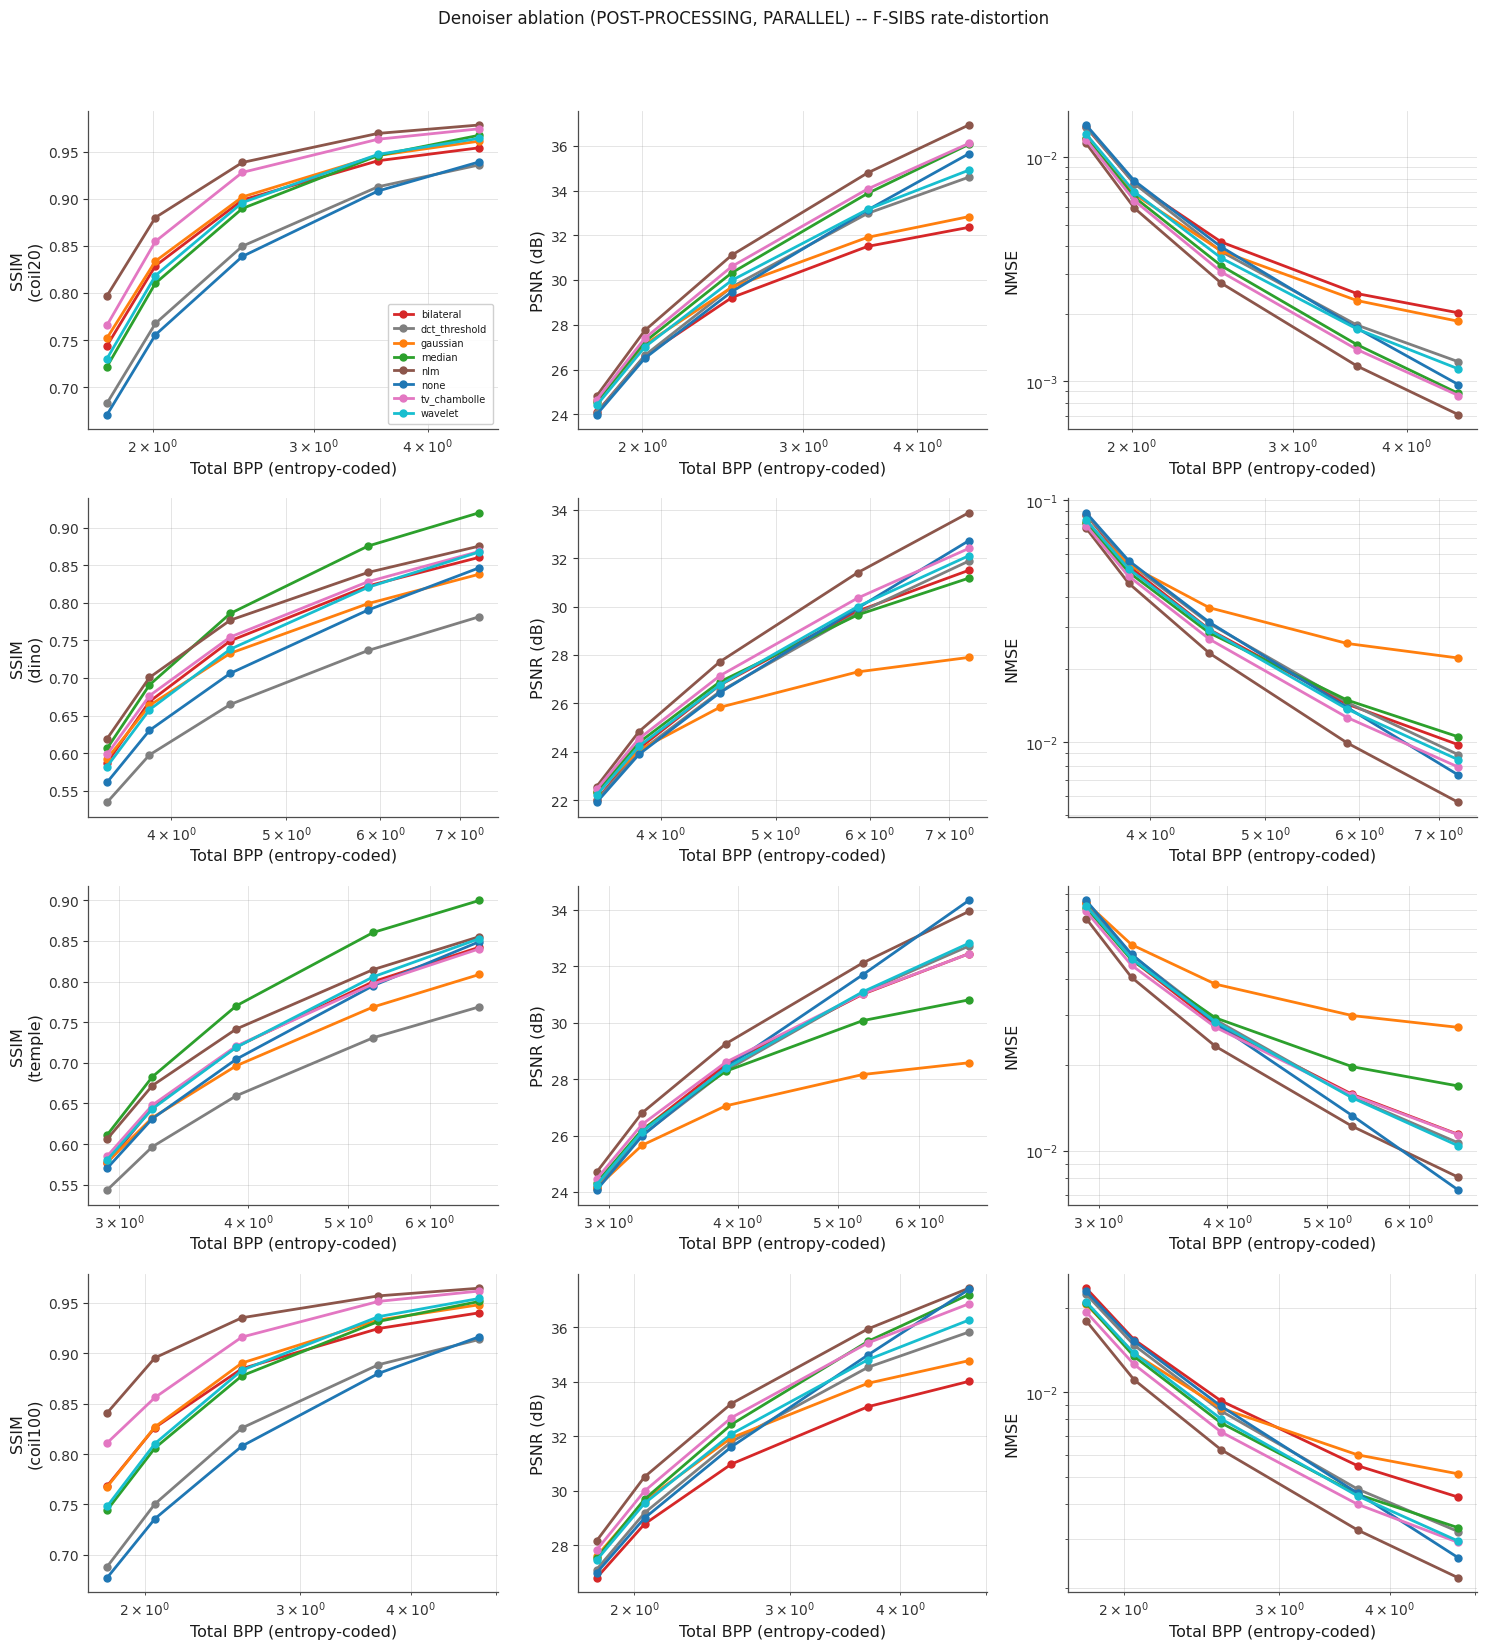

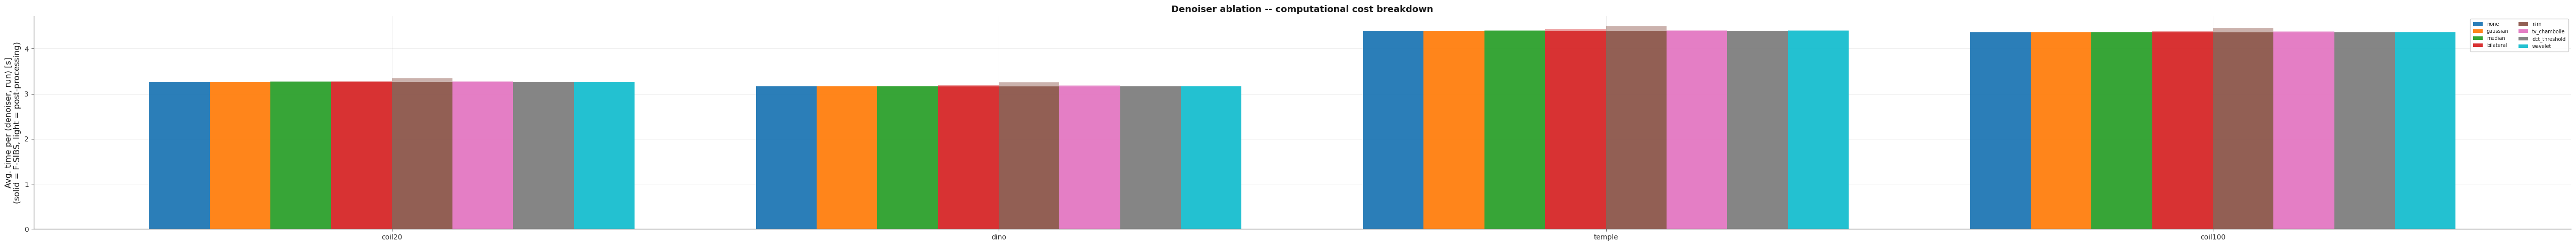

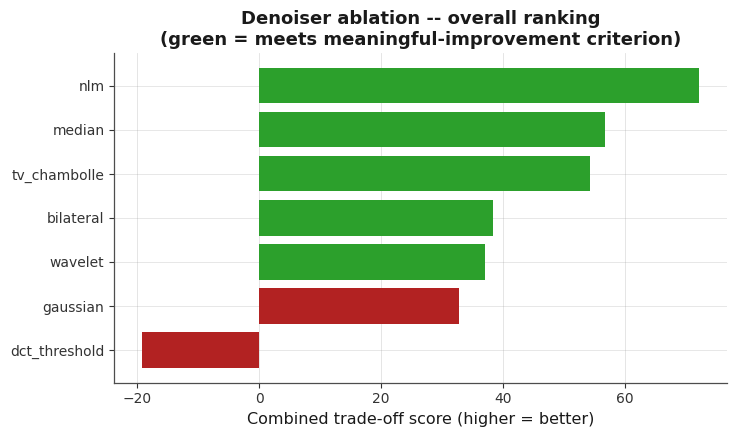


Saved tables: /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_raw_runs.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_rd_curve_by_dataset_denoiser_k.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_summary_by_dataset.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_vs_baseline_per_dataset.csv , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_overall_ranking.csv
Saved figures: /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_rd_curves_ssim_psnr_nmse.png , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_time_breakdown.png , /home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/experiment_denoiser/denoise_overall_ranking.png
E12 self-registered in EXPERIMENT_MANIFEST:

In [19]:
# ============================================================
# EXPERIMENT 12 - Denoiser Ablation (POST-PROCESSING with PARALLEL PROCESSING)
# ============================================================
# Pipeline:
#   1. F-SIBS federation + sparse coding on ORIGINAL images
#   2. For each denoiser: apply denoiser to the RECONSTRUCTION
#      as post-processing to reduce compression artifacts
#   3. Score the enhanced reconstruction against the ORIGINAL
#
# Key properties:
#   - BPP is identical for all denoisers (post-processing)
#   - Parallel processing across (dataset, run) combinations
#   - No checkpoint saving (full re-run)
# ============================================================

import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
import time as _dn_time

EXP_DENOISE_METHODS = ["none"] + [d for d in EXP_DENOISE_USER_SELECTION
                                  if d in DENOISER_REGISTRY and d != "none"]

print("Denoiser experiment (POST-PROCESSING, PARALLEL) -- active denoisers:")
for _d in EXP_DENOISE_METHODS:
    print("  %-14s %s" % (_d, DENOISER_REGISTRY[_d]["params"]))

_dn_pick_group = _pick_group

EXP_DENOISE_DATASETS = [ds for ds in SELECTED_DATASETS if ds in POOLS]
EXP_DENOISE_GROUPS = {}
for ds in EXP_DENOISE_DATASETS:
    cfg, g = _dn_pick_group(ds)
    if g is not None:
        EXP_DENOISE_GROUPS[ds] = (cfg, g)

if not EXP_DENOISE_GROUPS:
    print("Skipped: denoiser experiment -- no selected dataset provides a usable federated node group.")
else:
    _vname_dn, _vfn_dn = next(iter(ACTIVE_F_SIBS_VARIANTS.items()))
    _alg_dn = F_SIBS_VARIANT_TO_SIBS.get(_vname_dn, "SIBS1")
    print("\nDenoiser experiment will run on %d dataset(s): %s"
          % (len(EXP_DENOISE_GROUPS),
             ", ".join("%s (%s, group %s, N=%d)"
                       % (ds, cfg, g["group_id"], min(len(g["node_idx"]), EXP_DENOISE_MAX_NODES))
                       for ds, (cfg, g) in EXP_DENOISE_GROUPS.items())))
    print("F-SIBS config: variant=%s (local encoder %s), DELTA=%d, K_SUMMARY=%d, "
          "K_GLOBAL=%d, N_ROUNDS_FULL=%d, tau=%.2f, K_SWEEP=%s, %d runs/configuration"
          % (_vname_dn, _alg_dn, DELTA, K_SUMMARY, K_GLOBAL, N_ROUNDS_FULL,
             EXP_DENOISE_TAU, EXP_DENOISE_K_SWEEP, EXP_DENOISE_N_RUNS))
    print("NOTE: Federation runs on ORIGINAL images; denoiser applied AFTER reconstruction.")

    _dn_out_dir = os.path.join(FIG_DIR, "denoiser_experiment")
    _dn_results_dir = os.path.join(RESULTS_DIR, "experiment_denoiser")
    os.makedirs(_dn_out_dir, exist_ok=True)
    os.makedirs(_dn_results_dir, exist_ok=True)

    def _dn_save_table(df, name):
        p1 = os.path.join(_dn_results_dir, name + ".csv")
        p2 = os.path.join(_dn_out_dir, name + ".csv")
        df.to_csv(p1, index=False)
        df.to_csv(p2, index=False)
        return p1

    def _dn_save_figure(fig, name):
        p1 = os.path.join(_dn_results_dir, name + ".png")
        p2 = os.path.join(_dn_out_dir, name + ".png")
        fig.savefig(p1, dpi=200, bbox_inches="tight")
        fig.savefig(p2, dpi=200, bbox_inches="tight")
        return p1

    # -----------------------------------------------------------
    # PARALLEL PROCESSING WORKER FUNCTION
    # -----------------------------------------------------------
    def process_single_run(args):
        """Process one (dataset, run) combination with all denoisers."""
        ds, run = args
        
        cfg, g = EXP_DENOISE_GROUPS[ds]
        node_idx = g["node_idx"][:EXP_DENOISE_MAX_NODES]
        N_nodes = len(node_idx)
        imgs_orig = [POOLS[ds][i]["img"] for i in node_idx]
        Phi_ds = PHI[ds]
        h, w = GEOMETRY[ds] if ds in GEOMETRY else imgs_orig[0].shape
        n_px = h * w
        seed = 42 + run

        # STEP A: Federation on ORIGINAL images (once per run)
        t1 = _dn_time.time()
        try:
            fed = _vfn_dn(imgs_orig, Phi_ds, DELTA, K_SUMMARY, K_global=K_GLOBAL,
                         n_rounds=N_ROUNDS_FULL, tau=EXP_DENOISE_TAU, eps_conv=EPS_CONV,
                         seed=seed, return_transmitted_vectors=True)
        except Exception as e:
            print(f"  [ERROR] federation (dataset={ds}, run={run}) -> {e}")
            return []
            
        all_vecs = np.concatenate(
            [v for v in fed["transmitted_vectors_history"] if v.shape[1] > 0], axis=1
        ) if sum(v.shape[1] for v in fed["transmitted_vectors_history"]) > 0 else np.zeros((h, 0))
        
        if all_vecs.shape[1] > 0:
            q, _ = quantize_coeffs(all_vecs.ravel(), bits=DYNAMIC_SSIM_BITS_COEFF)
            uplink_entropy_bits = float(_entropy_bits_per_symbol(q) * all_vecs.size)
        else:
            uplink_entropy_bits = 0.0
        federated_comm_bpp = uplink_entropy_bits / (N_nodes * n_px)

        Psi_g = fed["global_dict"]
        if Psi_g.shape[1] > 0:
            Phi_aug = np.column_stack([Phi_ds, Psi_g])
            nrm = np.linalg.norm(Phi_aug, axis=0, keepdims=True)
            nrm[nrm < 1e-12] = 1.0
            Phi_aug = Phi_aug / nrm
        else:
            Phi_aug = Phi_ds
        N_dict = Phi_aug.shape[1]

        # STEP B: Sparse coding for each k (cache reconstructions)
        _cached_Xh = {}
        _cached_coef_bpps = {}
        for k in EXP_DENOISE_K_SWEEP:
            Xh_list = []
            coef_bpps = []
            for X_orig in imgs_orig:
                Xh, K_col, idx, coef = _run_algorithm_generic(
                    _alg_dn, X_orig, Phi_aug, DELTA,
                    lambda xo, et, ph, off, _k=k: _encode_column_fixed(xo, et, ph, off, _k))
                Xh = np.clip(Xh, 0, 255)
                enc = entropy_code_sparse_representation(idx, coef, [k], N_dict, 
                                                        bits_coeff=DYNAMIC_SSIM_BITS_COEFF)
                coef_bpps.append(enc["entropy_bits"] / n_px)
                Xh_list.append(Xh)
            _cached_Xh[k] = Xh_list
            _cached_coef_bpps[k] = float(np.mean(coef_bpps))

        fsibs_time_s = _dn_time.time() - t1

        # STEP C: Apply each denoiser as POST-PROCESSING
        _task_rows = []
        for denoiser in EXP_DENOISE_METHODS:
            denoise_fn = DENOISER_REGISTRY[denoiser]["fn"]
            
            for k in EXP_DENOISE_K_SWEEP:
                ssims, psnrs, nmses = [], [], []
                t_dn_start = _dn_time.time()
                
                for X_orig, Xh in zip(imgs_orig, _cached_Xh[k]):
                    # POST-PROCESSING: denoiser applied to reconstruction
                    Xh_enhanced = np.clip(denoise_fn(Xh), 0, 255)
                    # Score enhanced reconstruction vs. ORIGINAL
                    ssims.append(ssim(X_orig, Xh_enhanced))
                    psnrs.append(psnr(X_orig, Xh_enhanced))
                    nmses.append(nmse(X_orig, Xh_enhanced))
                    
                denoise_time_s = _dn_time.time() - t_dn_start
                coef_bpp = _cached_coef_bpps[k]
                total_bpp = coef_bpp + federated_comm_bpp
                
                _task_rows.append({
                    "dataset": ds, "config": cfg, "group_id": g["group_id"],
                    "denoiser": denoiser, "N_nodes": N_nodes, "run": run, "k": k,
                    "achieved_SSIM": float(np.mean(ssims)),
                    "achieved_PSNR": float(np.mean(psnrs)),
                    "achieved_NMSE": float(np.mean(nmses)),
                    "coefficient_BPP_entropy_coded": coef_bpp,
                    "federated_communication_BPP": federated_comm_bpp,
                    "total_BPP_entropy_coded": total_bpp,
                    "compression_ratio": 8.0 / total_bpp,
                    "denoise_time_s": denoise_time_s,
                    "fsibs_time_s": fsibs_time_s,
                    "total_time_s": fsibs_time_s + denoise_time_s,
                })

        return _task_rows

    # -----------------------------------------------------------
    # PARALLEL EXECUTION
    # -----------------------------------------------------------
    print("\nStarting PARALLEL processing...")
    num_cpus = mp.cpu_count()
    num_tasks = len(EXP_DENOISE_GROUPS) * EXP_DENOISE_N_RUNS
    num_workers = min(num_cpus, num_tasks)
    
    print(f"Available CPUs: {num_cpus}")
    print(f"Total tasks: {num_tasks} ({len(EXP_DENOISE_GROUPS)} datasets × {EXP_DENOISE_N_RUNS} runs)")
    print(f"Using {num_workers} workers")
    
    EXP_DENOISE_ROWS = []
    tasks = [(ds, run) for ds in EXP_DENOISE_GROUPS for run in range(EXP_DENOISE_N_RUNS)]
    
    # Use ProcessPoolExecutor for true parallelism
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        # Submit all tasks
        future_to_task = {executor.submit(process_single_run, task): task 
                         for task in tasks}
        
        # Collect results with progress bar
        for future in tqdm(as_completed(future_to_task), 
                          total=len(tasks), 
                          desc="Parallel processing",
                          bar_format=PBAR_FORMAT):
            task = future_to_task[future]
            try:
                result_rows = future.result()
                EXP_DENOISE_ROWS.extend(result_rows)
            except Exception as e:
                print(f"  [ERROR] Task {task} failed: {e}")

    print(f"\nCompleted! Collected {len(EXP_DENOISE_ROWS)} result rows.")

    # -----------------------------------------------------------
    # SAVE AND AGGREGATE RESULTS
    # -----------------------------------------------------------
    EXP_DENOISE_RAW_DF = pd.DataFrame(EXP_DENOISE_ROWS)
    _dn_raw_path = _dn_save_table(EXP_DENOISE_RAW_DF, "denoise_raw_runs")

    # Aggregate over runs
    _rd_metric_cols = ["achieved_SSIM", "achieved_PSNR", "achieved_NMSE",
                       "total_BPP_entropy_coded", "compression_ratio"]
    _rd_agg = EXP_DENOISE_RAW_DF.groupby(["dataset", "denoiser", "k"])[_rd_metric_cols].agg(["mean", "std"])
    _rd_agg.columns = ["%s_%s" % (c, s) for c, s in _rd_agg.columns]
    EXP_DENOISE_RD_DF = _rd_agg.reset_index()
    EXP_DENOISE_RD_DF["n_runs"] = EXP_DENOISE_N_RUNS
    _dn_rd_path = _dn_save_table(EXP_DENOISE_RD_DF, "denoise_rd_curve_by_dataset_denoiser_k")

    EXP_DENOISE_SUMMARY_DF = (
        EXP_DENOISE_RAW_DF.groupby(["dataset", "denoiser"])
        .agg(avg_BPP=("total_BPP_entropy_coded", "mean"),
             std_BPP=("total_BPP_entropy_coded", "std"),
             avg_compression_ratio=("compression_ratio", "mean"),
             avg_SSIM=("achieved_SSIM", "mean"), std_SSIM=("achieved_SSIM", "std"),
             avg_PSNR=("achieved_PSNR", "mean"), std_PSNR=("achieved_PSNR", "std"),
             avg_NMSE=("achieved_NMSE", "mean"), std_NMSE=("achieved_NMSE", "std"),
             avg_denoise_time_s=("denoise_time_s", "mean"),
             avg_fsibs_time_s=("fsibs_time_s", "mean"),
             avg_total_time_s=("total_time_s", "mean"),
             n_runs=("run", "nunique"))
        .reset_index())
    _dn_summary_path = _dn_save_table(EXP_DENOISE_SUMMARY_DF, "denoise_summary_by_dataset")

    print("\nDenoiser experiment -- summary per (dataset, denoiser), averaged over K_SWEEP and %d runs:" 
          % EXP_DENOISE_N_RUNS)
    print(EXP_DENOISE_SUMMARY_DF.round(4).to_string(index=False))

    # -----------------------------------------------------------
    # COMPARISON VS BASELINE
    # -----------------------------------------------------------
    EXP_DENOISE_MAX_BPP_TOLERANCE_PCT = 1.0     
    EXP_DENOISE_MIN_SSIM_IMPROVEMENT = 0.005    
    EXP_DENOISE_SCORE_W_SSIM_GAIN = 1000.0      
    EXP_DENOISE_SCORE_W_TIME = 0.05             

    _cmp_rows = []
    for ds in EXP_DENOISE_GROUPS:
        _s = EXP_DENOISE_SUMMARY_DF[EXP_DENOISE_SUMMARY_DF["dataset"] == ds]
        _base = _s[_s["denoiser"] == "none"]
        if _base.empty:
            continue
        _base = _base.iloc[0]
        for _, row in _s[_s["denoiser"] != "none"].iterrows():
            bpp_change_pct = (row["avg_BPP"] - _base["avg_BPP"]) / _base["avg_BPP"] * 100
            ssim_change = row["avg_SSIM"] - _base["avg_SSIM"]
            psnr_change_db = row["avg_PSNR"] - _base["avg_PSNR"]
            nmse_change_pct = (row["avg_NMSE"] - _base["avg_NMSE"]) / max(_base["avg_NMSE"], 1e-12) * 100
            time_overhead_pct = (row["avg_total_time_s"] - _base["avg_total_time_s"]) / _base["avg_total_time_s"] * 100
            _cmp_rows.append({
                "dataset": ds, "denoiser": row["denoiser"],
                "bpp_change_pct": bpp_change_pct, "ssim_change": ssim_change,
                "psnr_change_db": psnr_change_db, "nmse_change_pct": nmse_change_pct,
                "time_overhead_pct": time_overhead_pct,
                "meaningful_improvement": bool(
                    abs(bpp_change_pct) <= EXP_DENOISE_MAX_BPP_TOLERANCE_PCT and
                    ssim_change >= EXP_DENOISE_MIN_SSIM_IMPROVEMENT),
            })
    EXP_DENOISE_COMPARISON_DF = pd.DataFrame(_cmp_rows)
    _dn_comparison_path = _dn_save_table(EXP_DENOISE_COMPARISON_DF, "denoise_vs_baseline_per_dataset")

    print("\nDenoiser experiment -- per-dataset comparison against the no-denoising baseline:")
    print(EXP_DENOISE_COMPARISON_DF.round(4).to_string(index=False))

    # Overall ranking
    EXP_DENOISE_OVERALL_DF = (
        EXP_DENOISE_COMPARISON_DF.groupby("denoiser")
        .agg(mean_bpp_change_pct=("bpp_change_pct", "mean"),
             mean_ssim_change=("ssim_change", "mean"),
             mean_psnr_change_db=("psnr_change_db", "mean"),
             mean_nmse_change_pct=("nmse_change_pct", "mean"),
             mean_time_overhead_pct=("time_overhead_pct", "mean"),
             meaningful_improvement_on_n_datasets=("meaningful_improvement", "sum"),
             n_datasets=("dataset", "nunique"))
        .reset_index())
    
    EXP_DENOISE_OVERALL_DF["score"] = (
        EXP_DENOISE_OVERALL_DF["mean_ssim_change"] * EXP_DENOISE_SCORE_W_SSIM_GAIN
        - EXP_DENOISE_OVERALL_DF["mean_time_overhead_pct"] * EXP_DENOISE_SCORE_W_TIME)
        
    EXP_DENOISE_OVERALL_DF["meaningful_improvement_overall"] = (
        EXP_DENOISE_OVERALL_DF["meaningful_improvement_on_n_datasets"] == EXP_DENOISE_OVERALL_DF["n_datasets"])
    EXP_DENOISE_OVERALL_DF = EXP_DENOISE_OVERALL_DF.sort_values("score", ascending=False)
    _dn_overall_path = _dn_save_table(EXP_DENOISE_OVERALL_DF, "denoise_overall_ranking")

    print("\nDenoiser experiment -- OVERALL ranking:")
    print(EXP_DENOISE_OVERALL_DF.round(4).to_string(index=False))

    _meaningful = EXP_DENOISE_OVERALL_DF[EXP_DENOISE_OVERALL_DF["meaningful_improvement_overall"]]
    if not _meaningful.empty:
        _best = _meaningful.iloc[0]
        print("\n==> BEST post-processing denoiser for F-SIBS: "
              "'%s' -- avg SSIM change %+.4f, avg PSNR change %+.3f dB, "
              "avg time overhead %.1f%%, meets the meaningful-improvement "
              "criterion (|BPP change| <= %.1f%%, SSIM gain >= %.3f) on %d/%d dataset(s)."
              % (_best["denoiser"], _best["mean_ssim_change"], _best["mean_psnr_change_db"],
                 _best["mean_time_overhead_pct"], EXP_DENOISE_MAX_BPP_TOLERANCE_PCT,
                 EXP_DENOISE_MIN_SSIM_IMPROVEMENT, _best["meaningful_improvement_on_n_datasets"], _best["n_datasets"]))
    else:
        _best_overall = EXP_DENOISE_OVERALL_DF.iloc[0] if len(EXP_DENOISE_OVERALL_DF) else None
        print("\n==> No denoiser met the meaningful-improvement criterion "
              "(|BPP change| <= %.1f%% together with SSIM gain >= %.3f) on "
              "every selected dataset -- post-processing denoising as tested "
              "here does not reliably improve reconstruction quality."
              % (EXP_DENOISE_MAX_BPP_TOLERANCE_PCT, EXP_DENOISE_MIN_SSIM_IMPROVEMENT))
        if _best_overall is not None:
            print("    Closest / least-bad option by the combined score: '%s' "
                  "(avg SSIM change %+.4f, avg time overhead %.1f%%)."
                  % (_best_overall["denoiser"], _best_overall["mean_ssim_change"], _best_overall["mean_time_overhead_pct"]))

    # -----------------------------------------------------------
    # FIGURES
    # -----------------------------------------------------------
    _dn_datasets_plotted = list(EXP_DENOISE_GROUPS.keys())
    _n_ds = len(_dn_datasets_plotted)
    _dn_colors = plt.cm.tab10(np.linspace(0, 0.9, len(EXP_DENOISE_METHODS)))
    _dn_color_map = dict(zip(EXP_DENOISE_METHODS, _dn_colors))

    # Fig 1: SSIM / PSNR / NMSE vs. BPP
    fig, axes = plt.subplots(_n_ds, 3, figsize=(15, 4.2 * _n_ds), squeeze=False)
    for _i, ds in enumerate(_dn_datasets_plotted):
        _sub = EXP_DENOISE_RD_DF[EXP_DENOISE_RD_DF["dataset"] == ds]
        for denoiser, _curve in _sub.groupby("denoiser"):
            _curve = _curve.sort_values("total_BPP_entropy_coded_mean")
            _kw = dict(color=_dn_color_map[denoiser], marker="o", lw=2, markersize=5, label=denoiser)
            axes[_i][0].plot(_curve["total_BPP_entropy_coded_mean"], _curve["achieved_SSIM_mean"], **_kw)
            axes[_i][1].plot(_curve["total_BPP_entropy_coded_mean"], _curve["achieved_PSNR_mean"], **_kw)
            axes[_i][2].plot(_curve["total_BPP_entropy_coded_mean"], _curve["achieved_NMSE_mean"], **_kw)
        axes[_i][0].set_ylabel("SSIM\n(%s)" % ds)
        axes[_i][1].set_ylabel("PSNR (dB)")
        axes[_i][2].set_ylabel("NMSE")
        for _ax in axes[_i]:
            _ax.set_xlabel("Total BPP (entropy-coded)")
            _ax.set_xscale("log")
            _ax.grid(True, which="both", alpha=0.3)
        axes[_i][2].set_yscale("log")
    axes[0][0].legend(fontsize=7, loc="lower right")
    fig.suptitle("Denoiser ablation (POST-PROCESSING, PARALLEL) -- F-SIBS rate-distortion", fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    _dn_fig1_path = _dn_save_figure(fig, "denoise_rd_curves_ssim_psnr_nmse")
    plt.show()

    # Fig 2: Time breakdown
    _time_piv_dn = EXP_DENOISE_SUMMARY_DF.pivot(index="dataset", columns="denoiser", 
                                                values="avg_denoise_time_s").reindex(columns=EXP_DENOISE_METHODS)
    _time_piv_fs = EXP_DENOISE_SUMMARY_DF.pivot(index="dataset", columns="denoiser", 
                                                values="avg_fsibs_time_s").reindex(columns=EXP_DENOISE_METHODS)
    fig2, ax2 = plt.subplots(figsize=(max(7, 1.6 * len(EXP_DENOISE_METHODS) * _n_ds), 5))
    _x = np.arange(_n_ds)
    _bw = 0.8 / len(EXP_DENOISE_METHODS)
    for _j, denoiser in enumerate(EXP_DENOISE_METHODS):
        _xs = _x + _j * _bw - 0.4 + _bw / 2
        _ftime = _time_piv_fs[denoiser].values
        _dtime = _time_piv_dn[denoiser].values
        ax2.bar(_xs, _ftime, width=_bw, color=_dn_color_map[denoiser], alpha=0.95, label=denoiser)
        ax2.bar(_xs, _dtime, width=_bw, bottom=_ftime, color=_dn_color_map[denoiser], alpha=0.45)
    ax2.set_xticks(_x)
    ax2.set_xticklabels(_dn_datasets_plotted)
    ax2.set_ylabel("Avg. time per (denoiser, run) [s]\n(solid = F-SIBS, light = post-processing)")
    ax2.set_title("Denoiser ablation -- computational cost breakdown")
    ax2.legend(fontsize=7, ncol=2)
    ax2.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    _dn_fig2_path = _dn_save_figure(fig2, "denoise_time_breakdown")
    plt.show()

    # Fig 3: Overall ranking
    fig3, ax3 = plt.subplots(figsize=(7.5, 4.5))
    _ov = EXP_DENOISE_OVERALL_DF.sort_values("score")
    _bar_colors = ["#2ca02c" if m else "#b22222" for m in _ov["meaningful_improvement_overall"]]
    ax3.barh(_ov["denoiser"], _ov["score"], color=_bar_colors)
    ax3.set_xlabel("Combined trade-off score (higher = better)")
    ax3.set_title("Denoiser ablation -- overall ranking\n(green = meets meaningful-improvement criterion)")
    ax3.grid(True, axis="x", alpha=0.3)
    plt.tight_layout()
    _dn_fig3_path = _dn_save_figure(fig3, "denoise_overall_ranking")
    plt.show()

    print("\nSaved tables:", _dn_raw_path, ",", _dn_rd_path, ",", _dn_summary_path, 
          ",", _dn_comparison_path, ",", _dn_overall_path)
    print("Saved figures:", _dn_fig1_path, ",", _dn_fig2_path, ",", _dn_fig3_path)

# Manifest registration
for _dn_name in ["denoise_raw_runs", "denoise_rd_curve_by_dataset_denoiser_k",
                 "denoise_summary_by_dataset", "denoise_vs_baseline_per_dataset",
                 "denoise_overall_ranking"]:
    for _dn_dir in [os.path.join(RESULTS_DIR, "experiment_denoiser"), 
                    os.path.join(FIG_DIR, "denoiser_experiment")]:
        if os.path.exists(os.path.join(_dn_dir, _dn_name + ".csv")):
            if _dn_name + ".csv" not in EXPERIMENT_MANIFEST[12]["tables"]:
                EXPERIMENT_MANIFEST[12]["tables"].append(_dn_name + ".csv")
            break

for _dn_name in ["denoise_rd_curves_ssim_psnr_nmse", "denoise_time_breakdown", 
                 "denoise_overall_ranking"]:
    for _dn_dir in [os.path.join(RESULTS_DIR, "experiment_denoiser"), 
                    os.path.join(FIG_DIR, "denoiser_experiment")]:
        if os.path.exists(os.path.join(_dn_dir, _dn_name + ".png")):
            if _dn_name + ".png" not in EXPERIMENT_MANIFEST[12]["figures"]:
                EXPERIMENT_MANIFEST[12]["figures"].append(_dn_name + ".png")
            break

print("E12 self-registered in EXPERIMENT_MANIFEST: %d table(s), %d figure(s)"
      % (len(EXPERIMENT_MANIFEST[12]["tables"]), len(EXPERIMENT_MANIFEST[12]["figures"])))

In [20]:
save_manifest(EXPERIMENT_MANIFEST, "E12")   # lets the F2 report notebook map this notebook's outputs

'/home/ahmed_omara/F_SIBS_Modular/F_SIBS_r_2026-09-21_1/results/manifests/E12.json'